# Main figures

## Setup

In [1]:
import time
_T0 = time.time()

import logging
import math
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator, FuncFormatter
from mpl_toolkits.axes_grid1 import make_axes_locatable
import seaborn as sns
from scipy import stats
from sklearn.metrics import roc_curve, roc_auc_score, auc, confusion_matrix
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test, multivariate_logrank_test
from IPython.display import display

%matplotlib inline
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="Could not find the number of physical cores")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

DATA = Path("source_data")
MAIN = DATA / "Main_Figure"
OUT = Path("outputs") / "main"
assert MAIN.is_dir(), "Start Jupyter in the statistical_analysis/ folder (it must contain source_data/)."
OUT.mkdir(parents=True, exist_ok=True)

FONT_SANS = ["Arial", "Liberation Sans", "Helvetica", "DejaVu Sans"]
BASE_RC = {"axes.unicode_minus": False, "pdf.fonttype": 42, "ps.fonttype": 42, "savefig.dpi": 300}

def reset_style(sns_style=None, sns_context="notebook", font_scale=1.0, rc=None):
    mpl.rcdefaults()
    if sns_style is not None:
        sns.set_theme(style=sns_style, context=sns_context, font_scale=font_scale)
    plt.rcParams.update(BASE_RC)
    if rc:
        plt.rcParams.update(rc)
    plt.rcParams["font.family"] = "sans-serif"
    plt.rcParams["font.sans-serif"] = FONT_SANS
    plt.rcParams["figure.dpi"] = 100

def save(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(OUT / f"{name}.{ext}", dpi=300, bbox_inches="tight", facecolor="white")
    print(f"[saved] {OUT / name}.png and .pdf")

SUMMARY = []

def _fmt_like(value, reported):
    if isinstance(value, (bool, np.bool_)):
        return str(bool(value)), str(bool(value)) == str(reported)
    if isinstance(value, str):
        return value, value == str(reported).strip()
    rep = str(reported).strip()
    try:
        float(rep)
    except ValueError:
        return str(value), str(value) == rep
    value = float(value)
    if "e" in rep.lower():
        mant = rep.lower().split("e")[0].lstrip("+-")
        nsig = sum(ch.isdigit() for ch in mant)
        s = f"{value:.{max(nsig - 1, 0)}e}"
        return s, float(s) == float(rep)
    if "." in rep:
        nd = len(rep.split(".")[1])
        s = f"{value:.{nd}f}"
        return s, s == f"{float(rep):.{nd}f}"
    s = f"{value:.0f}"
    return s, s == f"{float(rep):.0f}"

def check(panel, quantity, value, reported, source="legend", note=""):
    shown, ok = _fmt_like(value, reported)
    SUMMARY.append(dict(panel=panel, quantity=quantity, notebook=shown, reported=str(reported),
                        reported_in=source, match=bool(ok), note=note))

def ovr_auc(y_true, P, classes):
    y_true = np.asarray(y_true)
    P = np.asarray(P, dtype=float)
    point = [roc_auc_score((y_true == c).astype(int), P[:, j]) for j, c in enumerate(classes)]
    return pd.DataFrame({"class": classes, "AUC": point})

def pearson_report(x, y, label=""):
    res = stats.pearsonr(np.asarray(x, float), np.asarray(y, float), alternative="two-sided")
    ci = res.confidence_interval(confidence_level=0.95)
    n = len(x)
    print(f"{label}: n = {n}, r({n - 2}) = {res.statistic:.3f}, 95% CI [{ci.low:.3f}, {ci.high:.3f}], "
          f"two-sided p = {res.pvalue:.3e}")
    return dict(r=res.statistic, lo=ci.low, hi=ci.high, p=res.pvalue, n=n, df=n - 2)

def welch_stats(d1, d2):
    d1 = np.asarray(pd.Series(d1).dropna(), dtype=float)
    d2 = np.asarray(pd.Series(d2).dropna(), dtype=float)
    n1, n2 = len(d1), len(d2)
    mean1, mean2 = np.mean(d1), np.mean(d2)
    var1, var2 = np.var(d1, ddof=1), np.var(d2, ddof=1)
    res = stats.ttest_ind(d1, d2, equal_var=False, alternative="two-sided")
    se2 = var1 / n1 + var2 / n2
    df = se2 ** 2 / ((var1 / n1) ** 2 / (n1 - 1) + (var2 / n2) ** 2 / (n2 - 1))
    diff = mean1 - mean2
    tcrit = stats.t.ppf(0.975, df)
    pooled_sd = np.sqrt(((n1 - 1) * var1 + (n2 - 1) * var2) / (n1 + n2 - 2))
    g = (1 - 3 / (4 * (n1 + n2) - 9)) * diff / pooled_sd
    return dict(n1=n1, n2=n2, t=res.statistic, df=df, p=res.pvalue, g=g, mean_difference=diff,
                ci_lower=diff - tcrit * np.sqrt(se2), ci_upper=diff + tcrit * np.sqrt(se2))

Z95 = stats.norm.ppf(0.975)

def km_curve(T, E):
    kmf = KaplanMeierFitter().fit(np.asarray(T, float), np.asarray(E, int))
    et = kmf.event_table
    t = et.index.values.astype(float)
    n = et["at_risk"].values.astype(float)
    d = et["observed"].values.astype(float)
    S = kmf.survival_function_.iloc[:, 0].values
    assert np.allclose(S, np.cumprod(1 - d / n))
    with np.errstate(divide="ignore", invalid="ignore"):
        se = np.sqrt(np.cumsum(np.where(d > 0, d / (n * (n - d)), 0.0)))
        lower = S * np.exp(-Z95 * se)
        upper = np.minimum(1.0, S * np.exp(Z95 * se))
    lower[S <= 0] = np.nan
    upper[S <= 0] = np.nan
    cens = et["censored"].values > 0
    return dict(t=t, S=S, lower=lower, upper=upper, cens_t=t[cens], cens_S=S[cens],
                median=kmf.median_survival_time_)

def extended_breaks(dmin, dmax, m=5, Q=(1, 5, 2, 2.5, 4, 3), w=(0.25, 0.2, 0.5, 0.05)):
    n = len(Q)
    eps = np.finfo(float).eps * 100

    def simplicity(i, j, lmin, lmax, lstep):
        rem = lmin % lstep
        v = 1 if ((rem < eps or lstep - rem < eps) and lmin <= 0 <= lmax) else 0
        return 1 - i / (n - 1) - j + v

    def coverage(lmin, lmax):
        rng = dmax - dmin
        return 1 - 0.5 * ((dmax - lmax) ** 2 + (dmin - lmin) ** 2) / ((0.1 * rng) ** 2)

    def coverage_max(span):
        rng = dmax - dmin
        if span > rng:
            half = (span - rng) / 2
            return 1 - 0.5 * (2 * half ** 2) / ((0.1 * rng) ** 2)
        return 1

    def density(k, lmin, lmax):
        r = (k - 1) / (lmax - lmin)
        rt = (m - 1) / (max(lmax, dmax) - min(dmin, lmin))
        return 2 - max(r / rt, rt / r)

    def density_max(k):
        return 2 - (k - 1) / (m - 1) if k >= m else 1

    best = None
    best_score = -2
    j = 1
    while True:
        stop = False
        for i, q in enumerate(Q):
            sm = 1 - i / (n - 1) - j + 1
            if w[0] * sm + w[1] + w[2] + w[3] < best_score:
                stop = True
                break
            k = 2
            while True:
                dm = density_max(k)
                if w[0] * sm + w[1] + w[2] * dm + w[3] < best_score:
                    break
                delta = (dmax - dmin) / (k + 1) / j / q
                z = math.ceil(math.log10(delta))
                while True:
                    step = j * q * 10 ** z
                    cm = coverage_max(step * (k - 1))
                    if w[0] * sm + w[1] * cm + w[2] * dm + w[3] < best_score:
                        break
                    min_start = math.floor(dmax / step) * j - (k - 1) * j
                    max_start = math.ceil(dmin / step) * j
                    if min_start > max_start:
                        z += 1
                        continue
                    for start in range(min_start, max_start + 1):
                        lmin = start * (step / j)
                        lmax = lmin + step * (k - 1)
                        score = (w[0] * simplicity(i, j, lmin, lmax, step) + w[1] * coverage(lmin, lmax)
                                 + w[2] * density(k, lmin, lmax) + w[3])
                        if score > best_score:
                            best_score, best = score, (lmin, lmax, step)
                    z += 1
                k += 1
        if stop:
            break
        j += 1
    lmin, lmax, step = best
    return np.round(np.arange(lmin, lmax + step / 2, step), 10)

def survminer_p_label(p):
    return "p < 0.0001" if p < 1e-4 else f"p = {p:.2g}"

def ggsurvplot_like(groups, p_label, p_xy=(10, 0.10), figsize=(8, 8), conf_alpha=0.30, censor_ms=10,
                    legend_fs=19, curve_lw=3.4):
    fig, ax = plt.subplots(figsize=figsize)
    medians, tmax = [], 0.0
    for g in groups:
        k = km_curve(g["T"], g["E"])
        tmax = max(tmax, float(np.max(g["T"])))
        ax.fill_between(k["t"], k["lower"], k["upper"], step="post", color=g["color"], alpha=conf_alpha, lw=0)
        ax.step(k["t"], k["S"], where="post", color=g["color"], lw=curve_lw, ls=g["ls"], zorder=3)
        ax.plot(k["cens_t"], k["cens_S"], ls="none", marker="+", ms=censor_ms, mew=1.5, color=g["color"], zorder=4)
        if np.isfinite(k["median"]):
            medians.append(k["median"])
    if medians:
        ax.plot([0, max(medians)], [0.5, 0.5], color="black", lw=0.8, ls=(0, (3, 3)), zorder=2)
        for m in medians:
            ax.plot([m, m], [0, 0.5], color="black", lw=0.8, ls=(0, (3, 3)), zorder=2)
    ax.text(p_xy[0], p_xy[1], p_label, fontsize=28, ha="left", va="center")
    ax.set_xlabel("Time (Months)", fontsize=25, fontweight="bold")
    ax.set_ylabel("Survival Probability", fontsize=25, fontweight="bold")
    ax.set_ylim(-0.05, 1.05)
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.2f}"))
    breaks = extended_breaks(0.0, tmax)
    ax.set_xlim(-0.05 * breaks[-1], 1.05 * breaks[-1])
    ax.set_xticks(breaks)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_linewidth(1.5)
    ax.tick_params(labelsize=20, width=1.5, length=6, colors="black")
    handles = [(Patch(facecolor=g["color"], alpha=conf_alpha, edgecolor="none"),
                Line2D([0], [0], color=g["color"], lw=curve_lw, ls=g["ls"], marker="+", ms=12, mew=1.5))
               for g in groups]
    ax.legend(handles, [g["label"] for g in groups], loc="upper center", bbox_to_anchor=(0.5, -0.14),
              ncol=len(groups), frameon=False, prop=dict(size=legend_fs, weight="bold"),
              handlelength=2.2, columnspacing=1.2)
    return fig, ax

CLASSES = ["Epithelial pattern", "Glial histology", "Meningothelial Histology", "Schwannian histology"]
CLASS_SHORT = ["Epithelial", "Glial", "Meningioma", "Schwannian"]

## Fig 2b

n   mean    sd
GPU        Task                    
RTX 4090   Mitosis  10   39.1   4.5
           MIB      10   85.1   3.9
RTX A4500  Mitosis  10   71.4  26.7
           MIB      10  122.4   6.9
RTX 4070   Mitosis  10  110.6   6.4
           MIB      10  141.4   3.3
RTX 3070   Mitosis  10  129.6   5.4
           MIB      10  157.4   5.3
RTX 4060   Mitosis  10  137.2   8.0
           MIB      10  183.2  13.1
RTX 2060   Mitosis  10  147.4   5.0
           MIB      10  245.8   7.8
GTX 1650Ti Mitosis  10  125.9  10.9
           MIB      10  337.8  24.5

[saved] outputs\main\Fig2b_GPU.png and .pdf


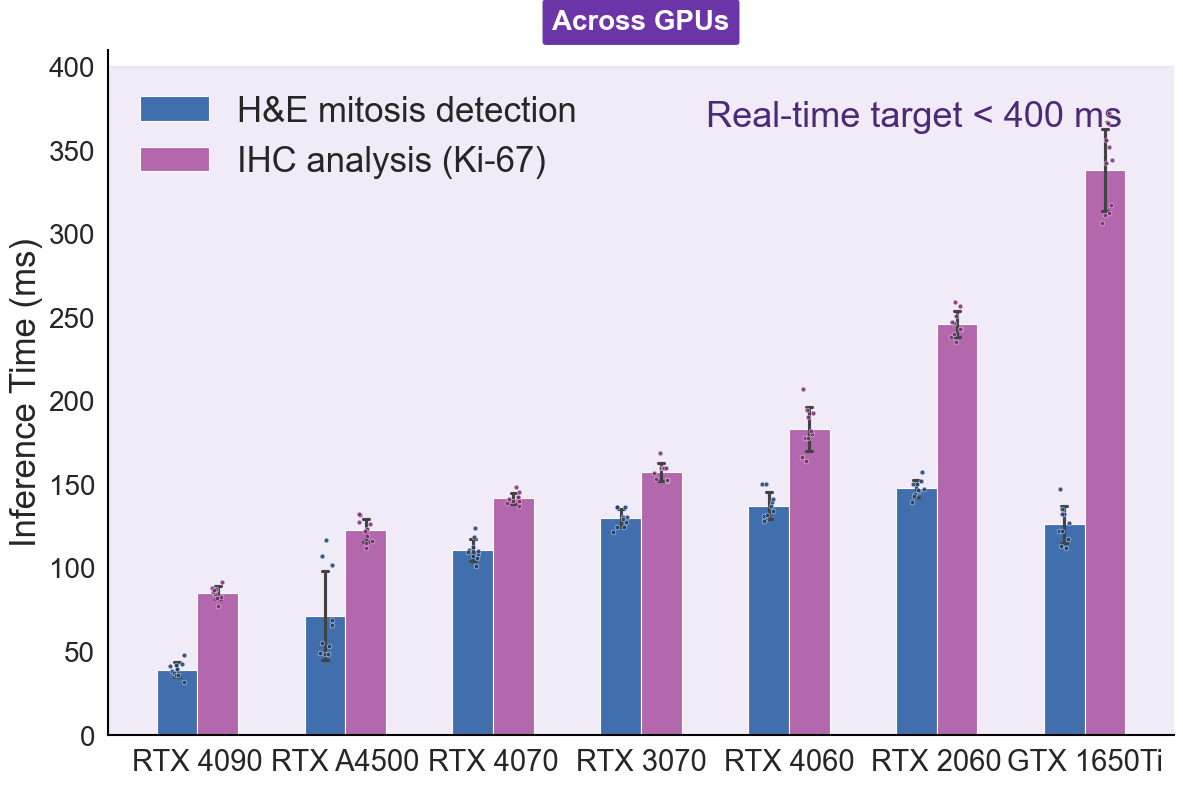

In [2]:
reset_style("white", rc={"axes.linewidth": 1.0, "axes.edgecolor": "#9AA7B8", "xtick.labelsize": 21,
                         "ytick.labelsize": 20, "axes.labelsize": 25, "legend.fontsize": 25})
FONT_SIZE_LEGEND, FONT_SIZE_REAL_TIME_LABEL = 25, 26
LEGEND_BBOX_TO_ANCHOR = (0.0, 0.98)

df = pd.read_csv(MAIN / "fig2" / "2b_inference_time_gpu.csv")
gpu_order = ["RTX 4090", "RTX A4500", "RTX 4070", "RTX 3070", "RTX 4060", "RTX 2060", "GTX 1650Ti"]
task_order = ["Mitosis", "MIB"]
palette = {"Mitosis": "#2F6CC0", "MIB": "#C05AB8"}
point_palette = {"Mitosis": "#173F75", "MIB": "#7A2D73"}

summ = (df.groupby(["GPU", "Task"])["Time (ms)"].agg(n="count", mean="mean", sd="std")
          .reindex(pd.MultiIndex.from_product([gpu_order, task_order], names=["GPU", "Task"])))
display(summ.round(1))
check("2b", "GPU: runs per device and task", summ["n"].min() if summ["n"].nunique() == 1 else -1, "10")
check("2b", "GPU: every device has mean < 400 ms for both tasks", bool((summ["mean"] < 400).all()), "True")

fig, ax1 = plt.subplots(figsize=(12, 8))
sns.barplot(data=df, x="GPU", y="Time (ms)", hue="Task", hue_order=task_order, order=gpu_order,
            palette=palette, errorbar="sd", capsize=0.08, width=0.55, edgecolor="white", linewidth=0.8, ax=ax1)
rng = np.random.default_rng(1)
group_width, n_tasks = 0.55, len(task_order)
single_bar_width = group_width / n_tasks
for i, g in enumerate(gpu_order):
    for j, task in enumerate(task_order):
        values = df.loc[(df["GPU"] == g) & (df["Task"] == task), "Time (ms)"].to_numpy()
        center = i + (j - (n_tasks - 1) / 2) * single_bar_width
        x_positions = center + rng.uniform(-single_bar_width * 0.18, single_bar_width * 0.18, size=len(values))
        ax1.scatter(x_positions, values, s=12, color=point_palette[task], edgecolor="white",
                    linewidth=0.35, alpha=0.85, zorder=4)
ax1.axhspan(0, 400, color="#7B3FB2", alpha=0.10, zorder=0)
ax1.text(len(gpu_order) - 0.75, 380, "Real-time target < 400 ms", ha="right", va="top",
         fontsize=FONT_SIZE_REAL_TIME_LABEL, color="#4B2A77")
ax1.set_xlabel("")
ax1.set_ylabel("Inference Time (ms)")
ax1.set_ylim(0, 410)
ax1.set_xticks(range(len(gpu_order)))
ax1.set_xticklabels(gpu_order, rotation=0, ha="center")
handles, labels = ax1.get_legend_handles_labels()
ax1.legend(handles, ["H&E mitosis detection", "IHC analysis (Ki-67)"], title=None, loc="upper left",
           bbox_to_anchor=LEGEND_BBOX_TO_ANCHOR, frameon=False, ncol=1, fontsize=FONT_SIZE_LEGEND)
ax1.text(0.5, 1.04, "Across GPUs", transform=ax1.transAxes, ha="center", va="center", fontsize=20,
         color="white", fontweight="bold",
         bbox=dict(boxstyle="round,pad=0.35,rounding_size=0.12", facecolor="#6B35A8", edgecolor="none"))
for side in ("left", "bottom"):
    ax1.spines[side].set_visible(True); ax1.spines[side].set_linewidth(1.5); ax1.spines[side].set_color("black")
for side in ("right", "top"):
    ax1.spines[side].set_visible(False)
plt.tight_layout()
save(fig, "Fig2b_GPU")
plt.show()

n     mean      sd
Device     Task                                      
i9-14900HX H&E mitosis detection  10    330.0    24.2
           IHC Ki-67 analysis     10   3930.9   795.3
i7-13620H  H&E mitosis detection  10    376.4    41.3
           IHC Ki-67 analysis     10   6750.9  1254.7
i5-1235U   H&E mitosis detection  10    430.7     9.8
           IHC Ki-67 analysis     10   9789.8  1078.1
i7-1360P   H&E mitosis detection  10    907.6    95.6
           IHC Ki-67 analysis     10  10557.8  2618.8

[saved] outputs\main\Fig2b_CPU.png and .pdf


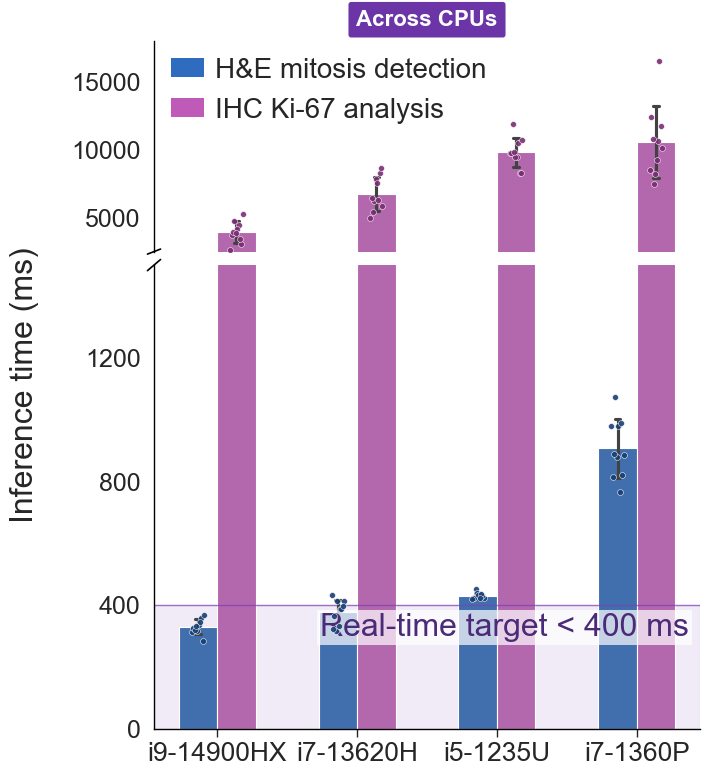

In [3]:
reset_style("white", rc={"font.size": 30, "axes.labelsize": 30, "xtick.labelsize": 30, "ytick.labelsize": 30,
                         "legend.fontsize": 30, "axes.linewidth": 1.0, "axes.edgecolor": "black"})
FONT_SIZE_X_TICKS, FONT_SIZE_Y_TICKS, FONT_SIZE_Y_AXIS_TITLE = 19, 18, 23
FONT_SIZE_LATENCY_TARGET, FONT_SIZE_LEGEND = 23, 20

raw = pd.read_csv(MAIN / "fig2" / "2b_inference_time_cpu.csv")
MITOSIS_LABEL, KI67_LABEL = "H&E mitosis detection", "IHC Ki-67 analysis"
df = pd.DataFrame({
    "Device": raw["CPU"].str.replace("_", "-", regex=False),
    "Task": raw["Task"].map({"Mitosis": MITOSIS_LABEL, "MIB": KI67_LABEL}),
    "Inference time (ms)": raw["Time (ms)"]})
cpu_order = ["i9-14900HX", "i7-13620H", "i5-1235U", "i7-1360P"]
task_order = [MITOSIS_LABEL, KI67_LABEL]

summ = (df.groupby(["Device", "Task"])["Inference time (ms)"].agg(n="count", mean="mean", sd="std")
          .reindex(pd.MultiIndex.from_product([cpu_order, task_order], names=["Device", "Task"])))
display(summ.round(1))
mit = summ.xs(MITOSIS_LABEL, level="Task")
check("2b", "CPU: runs per device and task", summ["n"].min() if summ["n"].nunique() == 1 else -1, "10")
check("2b", "CPU: configurations with mean mitosis latency < 400 ms (of 4)", int((mit["mean"] < 400).sum()), "2")

bar_palette = {MITOSIS_LABEL: "#2F6CC0", KI67_LABEL: "#C05AB8"}
point_palette = {MITOSIS_LABEL: "#173F75", KI67_LABEL: "#7A2D73"}
fig, (ax_top, ax_bottom) = plt.subplots(2, 1, sharex=True, figsize=(7, 8),
                                        gridspec_kw={"height_ratios": [1.0, 2.2], "hspace": 0.04})
group_width = 0.55
n_tasks = len(task_order)
single_bar_width = group_width / n_tasks
rng = np.random.default_rng(1)
point_positions = {}
for device_index, cpu in enumerate(cpu_order):
    for task_index, task in enumerate(task_order):
        values = df.loc[(df["Device"] == cpu) & (df["Task"] == task), "Inference time (ms)"].to_numpy()
        bar_center = device_index + (task_index - (n_tasks - 1) / 2) * single_bar_width
        offsets = np.linspace(-single_bar_width * 0.16, single_bar_width * 0.16, len(values))
        rng.shuffle(offsets)
        point_positions[(cpu, task)] = {"x": bar_center + offsets, "y": values}
for ax in [ax_top, ax_bottom]:
    sns.barplot(data=df, x="Device", y="Inference time (ms)", hue="Task", hue_order=task_order, order=cpu_order,
                palette=bar_palette, estimator="mean", errorbar="sd", capsize=0.08, width=group_width,
                edgecolor="white", linewidth=0.8, ax=ax)
    if ax.get_legend() is not None:
        ax.get_legend().remove()
    for cpu in cpu_order:
        for task in task_order:
            pos = point_positions[(cpu, task)]
            ax.scatter(pos["x"], pos["y"], s=18, color=point_palette[task], edgecolor="white",
                       linewidth=0.40, alpha=0.90, zorder=4, clip_on=True)
ax_bottom.set_ylim(0, 1500)
ax_top.set_ylim(2500, 18000)
ax_bottom.set_yticks([0, 400, 800, 1200])
ax_top.set_yticks([5000, 10000, 15000])
ax_bottom.axhspan(0, 400, color="#7B3FB2", alpha=0.10, zorder=0)
ax_bottom.axhline(400, color="#7B3FB2", linewidth=1.0, alpha=0.70, zorder=1)
ax_bottom.text(0.98, 0.25, "Real-time target < 400 ms", transform=ax_bottom.transAxes, ha="right", va="top",
               fontsize=FONT_SIZE_LATENCY_TARGET, color="#4B2A77",
               bbox={"facecolor": "white", "alpha": 0.70, "edgecolor": "none", "pad": 2})
ax_top.spines["bottom"].set_visible(False)
ax_bottom.spines["top"].set_visible(False)
ax_top.tick_params(axis="x", which="both", bottom=False, labelbottom=False)
ax_bottom.xaxis.tick_bottom()
d = 0.012
break_style = {"color": "black", "clip_on": False, "linewidth": 1.2}
ax_top.plot((-d, +d), (-d, +d), transform=ax_top.transAxes, **break_style)
ax_bottom.plot((-d, +d), (1 - d, 1 + d), transform=ax_bottom.transAxes, **break_style)
for ax in [ax_top, ax_bottom]:
    ax.spines["left"].set_visible(True); ax.spines["left"].set_linewidth(1.0); ax.spines["left"].set_color("black")
    ax.spines["right"].set_visible(False); ax.spines["top"].set_visible(False)
    ax.grid(False)
    ax.tick_params(axis="y", labelsize=FONT_SIZE_Y_TICKS, width=1.0, color="black")
ax_bottom.spines["bottom"].set_visible(True); ax_bottom.spines["bottom"].set_linewidth(1.0)
ax_bottom.spines["bottom"].set_color("black")
ax_bottom.tick_params(axis="x", labelsize=FONT_SIZE_X_TICKS, rotation=0, width=1.0)
for ax in [ax_top, ax_bottom]:
    ax.set_xlabel(""); ax.set_ylabel("")
fig.text(0.015, 0.50, "Inference time (ms)", ha="center", va="center", rotation="vertical",
         fontsize=FONT_SIZE_Y_AXIS_TITLE)
legend_handles = [Patch(facecolor=bar_palette[MITOSIS_LABEL], edgecolor="none", label=MITOSIS_LABEL),
                  Patch(facecolor=bar_palette[KI67_LABEL], edgecolor="none", label=KI67_LABEL)]
ax_top.legend(handles=legend_handles, loc="upper left", frameon=False, fontsize=FONT_SIZE_LEGEND,
              handlelength=1.2, handletextpad=0.4, borderaxespad=0.2)
ax_top.text(0.5, 1.10, "Across CPUs", transform=ax_top.transAxes, ha="center", va="center", fontsize=16,
            color="white", fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.35,rounding_size=0.12", facecolor="#6B35A8", edgecolor="none"))
fig.subplots_adjust(left=0.20, right=0.98, bottom=0.07, top=0.93)
save(fig, "Fig2b_CPU")
plt.show()

## Fig 3c

rows in file = 251; analysed = 244 (mitoses = 97, non-mitoses = 147); subjects = 5 (H00, H01, H02, H03, H04); detections scored 0 (undetected) = 14
AUC = 0.7872
Youden-optimal threshold = 31.10 (0-100 scale) = 0.311 (0-1 scale); sensitivity = 0.7423, specificity = 0.8503


,TP,FP,FN,precision,recall,F1
rule,,,,,,
score >= threshold,72,22,25,0.7660,0.7423,0.7539
score > threshold,71,22,26,0.7634,0.7320,0.7474


[saved] outputs\main\Fig3c.png and .pdf


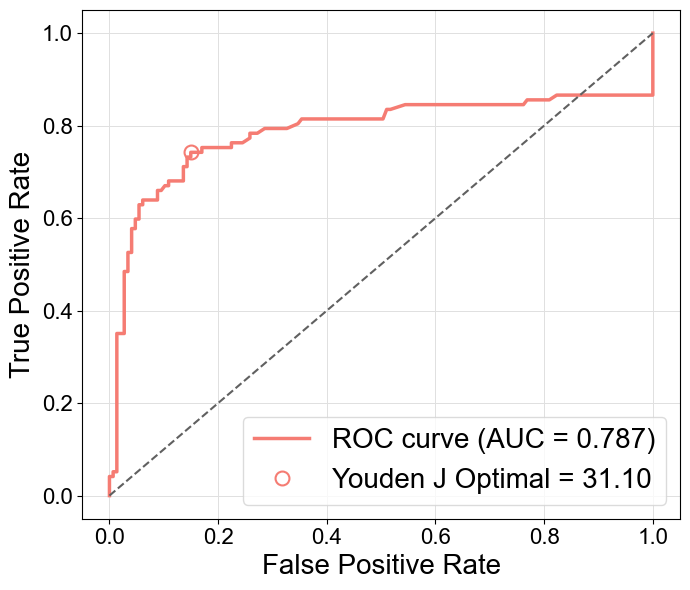

In [4]:
reset_style(rc={"font.family": "Arial"})
PALETTE_LIGHT = {"red_accent": "#F57C73", "grey": "#606060", "light_grey": "#E0E0E0"}

raw = pd.read_csv(MAIN / "fig3" / "3c_ICPR_roc.csv")
raw.columns = raw.columns.str.strip()
dfm = raw.copy()
dfm["Mitosis"] = dfm["Mitosis"].str.lower().map({"yes": 1, "no": 0})
mask = dfm["Confidence"].isin(["Undetected", "NOT Detected"])
dfm.loc[mask, "Confidence"] = 0
dfm["Confidence"] = pd.to_numeric(dfm["Confidence"], errors="coerce")
dfm = dfm.dropna()
y_true, y_scores = dfm["Mitosis"].astype(int).values, dfm["Confidence"].astype(float).values
subjects = dfm["Case ID"].str.strip('"').str.split("_").str[0]
print(f"rows in file = {len(raw)}; analysed = {len(dfm)} (mitoses = {y_true.sum()}, non-mitoses = {(1 - y_true).sum()}); "
      f"subjects = {subjects.nunique()} ({', '.join(sorted(subjects.unique()))}); "
      f"detections scored 0 (undetected) = {int(mask.sum())}")

fpr, tpr, thresholds = roc_curve(y_true, y_scores)
auc_score = roc_auc_score(y_true, y_scores)
optimal_idx = np.argmax(tpr - fpr)
optimal_threshold = thresholds[optimal_idx]
print(f"AUC = {auc_score:.4f}")
print(f"Youden-optimal threshold = {optimal_threshold:.2f} (0-100 scale) = {optimal_threshold / 100:.3f} (0-1 scale); "
      f"sensitivity = {tpr[optimal_idx]:.4f}, specificity = {1 - fpr[optimal_idx]:.4f}")
op_rows = []
for rule, pred in [("score >= threshold", y_scores >= optimal_threshold), ("score > threshold", y_scores > optimal_threshold)]:
    tp = int((pred & (y_true == 1)).sum()); fp = int((pred & (y_true == 0)).sum()); fn = int((~pred & (y_true == 1)).sum())
    prec, rec = tp / (tp + fp), tp / (tp + fn)
    op_rows.append(dict(rule=rule, TP=tp, FP=fp, FN=fn, precision=prec, recall=rec, F1=2 * prec * rec / (prec + rec)))
op = pd.DataFrame(op_rows).set_index("rule")
display(op.round(4))
F1_ONSIGHT = op.loc["score >= threshold", "F1"]

check("3c", "n detections", len(dfm), "244")
check("3c", "n mitoses / non-mitoses", f"{y_true.sum()}/{(1 - y_true).sum()}", "97/147", source="brief")
check("3c", "n subjects", subjects.nunique(), "5")
check("3c", "AUC", auc_score, "0.787")
check("3c", "Youden threshold (0-100 scale, panel label)", optimal_threshold, "31.10", source="submitted panel")
check("3c", "precision at threshold (>=)", op.loc["score >= threshold", "precision"], "0.7659", source="brief",
      note="72/94 = 0.76596; the brief truncates instead of rounding")
check("3c", "recall at threshold (>=)", op.loc["score >= threshold", "recall"], "0.7422", source="brief",
      note="72/97 = 0.74227; the brief truncates instead of rounding")
check("3c", "F1 at threshold (>=)", F1_ONSIGHT, "0.7539", source="brief")

plt.figure(figsize=(7, 6))
ax = plt.gca()
ax.plot(fpr, tpr, color=PALETTE_LIGHT["red_accent"], lw=2.5, label=f"ROC curve (AUC = {auc_score:.3f})")
ax.plot(fpr[optimal_idx], tpr[optimal_idx], "o", color=PALETTE_LIGHT["red_accent"], markersize=10, mew=1.5,
        mfc="none", label=f"Youden J Optimal = {optimal_threshold:.2f}")
ax.plot([0, 1], [0, 1], color=PALETTE_LIGHT["grey"], linestyle="--", lw=1.5)
ax.set_xlabel("False Positive Rate", fontsize=20)
ax.set_ylabel("True Positive Rate", fontsize=20)
ax.tick_params(axis="both", which="major", labelsize=16)
ax.legend(loc="lower right", fontsize=20, frameon=True, fancybox=True, edgecolor="lightgray")
ax.grid(True, linewidth=0.7, color=PALETTE_LIGHT["light_grey"])
plt.tight_layout()
save(plt.gcf(), "Fig3c")
plt.show()

## Fig 3d

,Method,F1 Score
0,OnSight,0.7539
1,SUTECH,0.7011
2,IPAL,0.6256
3,NEC,0.5570
4,DEFINIENS,0.3636


OnSight F1 recomputed from the Fig. 3c detections = 0.7539 (leaderboard file: 0.7539)


[saved] outputs\main\Fig3d.png and .pdf


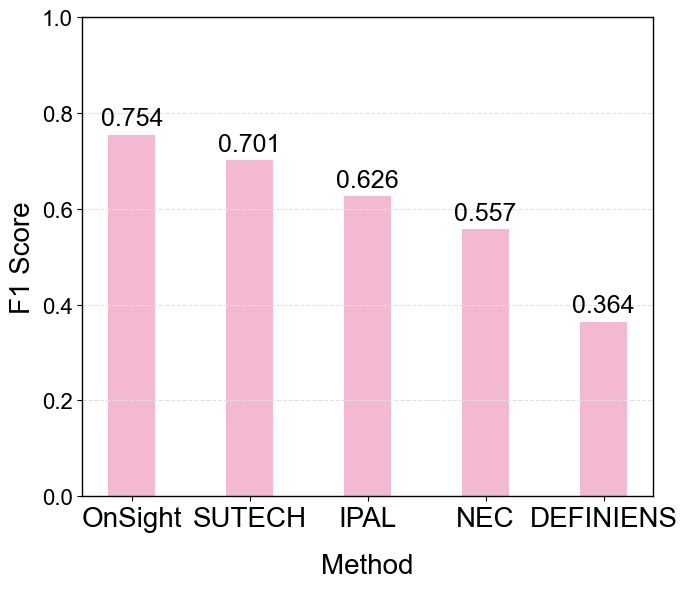

In [5]:
reset_style(rc={"font.family": "Arial"})
PALETTE_LIGHT = {"blue": "#F4B9D2", "grey": "#606060", "light_grey": "#E0E0E0"}
lb = pd.read_csv(MAIN / "fig3" / "3d_leaderboard.csv")
display(lb)
print(f"OnSight F1 recomputed from the Fig. 3c detections = {F1_ONSIGHT:.4f} (leaderboard file: "
      f"{lb.loc[lb.Method == 'OnSight', 'F1 Score'].item():.4f})")
for m, v in zip(lb["Method"], ["0.754", "0.701", "0.626", "0.557", "0.364"]):
    check("3d", f"F1 {m}", lb.loc[lb.Method == m, "F1 Score"].item(), v, source="submitted panel")
check("3d", "F1 OnSight recomputed from 3c data", F1_ONSIGHT, "0.754", source="submitted panel")

labels, f1_scores = lb["Method"].tolist(), lb["F1 Score"].to_numpy()
plt.figure(figsize=(7, 6))
ax = plt.gca()
x_pos = np.arange(len(labels))
ax.bar(x_pos, f1_scores, color=PALETTE_LIGHT["blue"], width=0.4)
for i, v in enumerate(f1_scores):
    ax.text(i, v + 0.02, f"{v:.3f}", ha="center", fontsize=18)
ax.set_xticks(x_pos)
ax.set_xticklabels(labels, fontsize=20)
ax.tick_params(axis="y", labelsize=16)
ax.set_ylim(0, 1.0)
ax.set_ylabel("F1 Score", fontsize=20)
ax.set_xlabel("Method", fontsize=20, labelpad=15)
ax.grid(True, axis="y", linestyle="--", color=PALETTE_LIGHT["light_grey"])
for spine in ax.spines.values():
    spine.set_visible(True); spine.set_color("black"); spine.set_linewidth(1)
plt.tight_layout()
save(plt.gcf(), "Fig3d")
plt.show()

## Fig 3e

n = 200 detections (YES = 64, NO = 136) from 6 subjects
AUC = 0.9782; Youden threshold = 45.30 (0-100) = 0.453 (0-1); sensitivity = 0.9531, specificity = 0.9191


[saved] outputs\main\Fig3e.png and .pdf


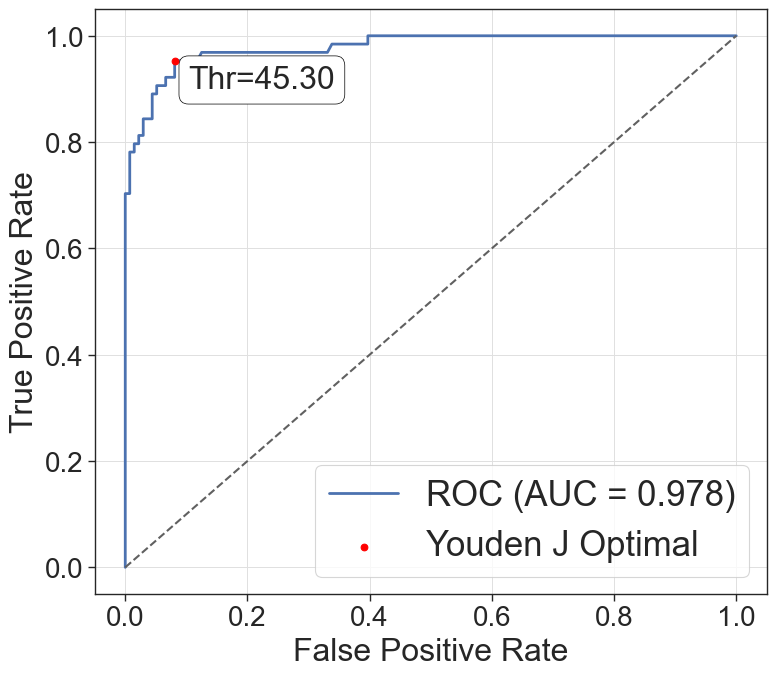

In [6]:
reset_style(rc={"font.family": "Arial"})
PALETTE_LIGHT = {"red_accent": "#F57C73", "grey": "#606060", "light_grey": "#E0E0E0"}
loc = pd.read_csv(MAIN / "fig3" / "3e_local_mitosis.csv")
loc.columns = loc.columns.str.strip()
y = loc["Mitosis"].astype(str).str.strip().str.lower().map({"yes": 1, "no": 0})
s = pd.to_numeric(loc["Score"], errors="coerce")
keep = y.notna() & s.notna()
y, s = y[keep].astype(int).values, s[keep].astype(float).values
cases = loc["Case"].ffill()[keep]
print(f"n = {len(y)} detections (YES = {y.sum()}, NO = {(1 - y).sum()}) from {cases.nunique()} subjects")
fpr, tpr, thresholds = roc_curve(y, s)
auc_score = roc_auc_score(y, s)
opt_idx = int(np.argmax(tpr - fpr))
opt_thr = float(thresholds[opt_idx])
print(f"AUC = {auc_score:.4f}; Youden threshold = {opt_thr:.2f} (0-100) = "
      f"{opt_thr / 100:.3f} (0-1); sensitivity = {tpr[opt_idx]:.4f}, specificity = {1 - fpr[opt_idx]:.4f}")
check("3e", "n detections", len(y), "200")
check("3e", "n YES / NO", f"{y.sum()}/{(1 - y).sum()}", "64/136", source="brief")
check("3e", "n subjects", cases.nunique(), "6")
check("3e", "AUC", auc_score, "0.978")
check("3e", "Youden threshold (0-100 scale, panel label)", opt_thr, "45.30", source="submitted panel")

reset_style("ticks", "paper", font_scale=1.5)
plt.figure(figsize=(8, 7))
plt.plot(fpr, tpr, color="#4C72B0", lw=2, label=f"ROC (AUC = {auc_score:.3f})")
plt.plot([0, 1], [0, 1], color=PALETTE_LIGHT["grey"], linestyle="--", lw=1.5)
plt.scatter(fpr[opt_idx], tpr[opt_idx], color="red", zorder=5, label="Youden J Optimal")
plt.annotate(f"Thr={opt_thr:.2f}", (fpr[opt_idx], tpr[opt_idx]), textcoords="offset points", xytext=(10, -20),
             ha="left", fontsize=23, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black", lw=0.5))
ax = plt.gca()
ax.set_xlabel("False Positive Rate", fontsize=23)
ax.set_ylabel("True Positive Rate", fontsize=23)
ax.tick_params(axis="both", labelsize=20)
plt.grid(True, linewidth=0.7, color=PALETTE_LIGHT["light_grey"])
plt.legend(loc="lower right", fontsize=25)
plt.tight_layout()
save(plt.gcf(), "Fig3e")
plt.show()

## Fig 3f

n = 16 image regions from 3 subjects (VAL75, VAL62, VAL17)
OnSight: n = 16, r(14) = 0.981, 95% CI [0.944, 0.993], two-sided p = 2.604e-11
QuPath: n = 16, r(14) = 0.950, 95% CI [0.859, 0.983], two-sided p = 1.802e-08


DeepLIIF: n = 16, r(14) = 0.945, 95% CI [0.846, 0.981], two-sided p = 3.444e-08


[saved] outputs\main\Fig3f.png and .pdf


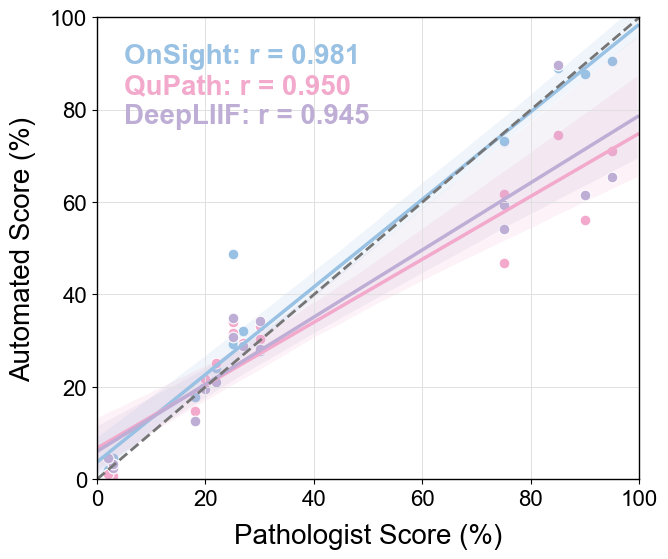

In [7]:
PALETTE_ADVANCED = {"teal": "#00796B", "dark_grey": "#424242", "medium_grey": "#757575", "light_grey": "#E0E0E0"}
reset_style(rc={"font.family": "Arial", "figure.facecolor": "white", "axes.titlesize": 18, "axes.labelsize": 16,
                "axes.titlepad": 12, "axes.labelpad": 10, "axes.edgecolor": "black", "axes.linewidth": 1.0,
                "xtick.labelsize": 16, "ytick.labelsize": 16, "legend.fontsize": 12,
                "grid.color": PALETTE_ADVANCED["light_grey"], "grid.linestyle": "-", "grid.linewidth": 0.7,
                "lines.linewidth": 2.5})
display_names = {"Onsight_Percentage": "OnSight", "Qupath_Percentage": "QuPath", "Deepliif_Percentage": "DeepLIIF"}
ki = pd.read_csv(MAIN / "fig3" / "3f_ki67_public.csv")
subjects = ki["Slide_ID"].str.split("_").str[0]
df_ki67 = ki.iloc[:, 1:].copy()
df_ki67.columns = ["Pathologist_Percentage", "Onsight_Time", "Onsight_Percentage", "Qupath_Time",
                   "Qupath_Percentage", "Deepliif_Time", "Deepliif_Percentage"]
df_ki67 = df_ki67.apply(pd.to_numeric, errors="coerce").dropna()
print(f"n = {len(df_ki67)} image regions from {subjects.nunique()} subjects ({', '.join(subjects.unique())})")
check("3f", "n image regions", len(df_ki67), "16")
check("3f", "n subjects", subjects.nunique(), "3")
expected = {"Onsight_Percentage": ("0.981", "0.944", "0.993", "2.60e-11"),
            "Qupath_Percentage": ("0.950", "0.859", "0.983", "1.80e-8"),
            "Deepliif_Percentage": ("0.945", "0.846", "0.981", "3.44e-8")}

fig, ax = plt.subplots(figsize=(7, 6))
methods = {"Onsight_Percentage": "#98C1E3", "Qupath_Percentage": "#F2A9CB", "Deepliif_Percentage": "#BEADD5"}
for i, (method, color) in enumerate(methods.items()):
    res = pearson_report(df_ki67["Pathologist_Percentage"], df_ki67[method], display_names[method])
    e = expected[method]
    check("3f", f"{display_names[method]} r", res["r"], e[0])
    check("3f", f"{display_names[method]} df", res["df"], "14")
    check("3f", f"{display_names[method]} r 95% CI lower", res["lo"], e[1])
    check("3f", f"{display_names[method]} r 95% CI upper", res["hi"], e[2])
    check("3f", f"{display_names[method]} p", res["p"], e[3])
    sns.regplot(x="Pathologist_Percentage", y=method, data=df_ki67,
                scatter_kws={"alpha": 1, "s": 60, "edgecolor": "white", "linewidths": 0.8},
                line_kws={"color": color, "linewidth": 2.5}, ci=95, n_boot=1000, seed=42, truncate=False,
                color=color, ax=ax)
    ax.text(0.05, 0.90 - 0.065 * i, f"{display_names[method]}: r = {res['r']:.3f}", transform=ax.transAxes,
            fontsize=20, weight="bold", color=color)
ax.plot([0, 100], [0, 100], color=PALETTE_ADVANCED["medium_grey"], linestyle="--", lw=2, label="Line of Identity")
ax.set_xlabel("Pathologist Score (%)", fontsize=20)
ax.set_ylabel("Automated Score (%)", fontsize=20)
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.grid(True, linewidth=0.7, color=PALETTE_ADVANCED["light_grey"])
for spine in ax.spines.values():
    spine.set_visible(True); spine.set_color("black"); spine.set_linewidth(1.0)
save(fig, "Fig3f")
plt.show()

## Fig 3g

OnSight: n = 16, mean = 0.2487 s, SD = 0.0456 s  -> label '0.25±0.05'


QuPath: n = 16, mean = 14.7931 s, SD = 3.9952 s  -> label '14.79±4.00'
DeepLIIF: n = 16, mean = 169.6250 s, SD = 27.9926 s  -> label '169.62±27.99'


[saved] outputs\main\Fig3g.png and .pdf


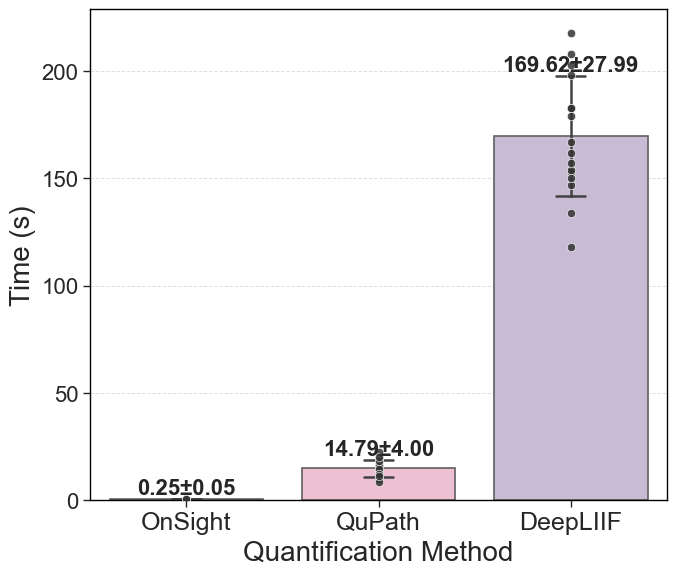

In [8]:
PALETTE_LIGHT = {"blue": "#A6C8E6", "pink": "#F4B9D2", "purple": "#C8B8D8", "grey": "#606060", "light_grey": "#E0E0E0"}
reset_style("ticks", "paper", font_scale=1.5,
            rc={"mathtext.fontset": "custom", "mathtext.rm": "sans", "mathtext.it": "sans:italic",
                "mathtext.bf": "sans:bold"})
METHOD_ORDER = ["OnSight", "QuPath", "DeepLIIF"]
METHOD_COLORS = {"OnSight": PALETTE_LIGHT["blue"], "QuPath": PALETTE_LIGHT["pink"], "DeepLIIF": PALETTE_LIGHT["purple"]}
tg = pd.read_csv(MAIN / "fig3" / "3g_ki67_comparison.csv")
time_df = tg[["Onsight Time", "Qupath Time", "Deepliif Time"]].copy()
time_df.columns = METHOD_ORDER
long_time_df = time_df.melt(var_name="Method", value_name="Time (s)")
long_time_df["Method"] = pd.Categorical(long_time_df["Method"], categories=METHOD_ORDER, ordered=True)
means = long_time_df.groupby("Method", observed=False)["Time (s)"].mean().reindex(METHOD_ORDER)
stds = long_time_df.groupby("Method", observed=False)["Time (s)"].std().reindex(METHOD_ORDER)
ns = long_time_df.groupby("Method", observed=False)["Time (s)"].count().reindex(METHOD_ORDER)
for m in METHOD_ORDER:
    print(f"{m}: n = {ns[m]}, mean = {means[m]:.4f} s, SD = {stds[m]:.4f} s  -> label '{means[m]:.2f}±{stds[m]:.2f}'")
for m, lab in zip(METHOD_ORDER, ["0.25±0.05", "14.79±4.00", "169.62±27.99"]):
    check("3g", f"{m} mean±SD (s)", f"{means[m]:.2f}±{stds[m]:.2f}", lab, source="submitted panel")
check("3g", "n regions per tool", int(ns.min()), "16")

fig, ax1 = plt.subplots(figsize=(7, 6))
sns.barplot(x="Method", y="Time (s)", hue="Method", data=long_time_df, order=METHOD_ORDER, hue_order=METHOD_ORDER,
            palette=METHOD_COLORS, legend=False, capsize=0.15, errorbar="sd", edgecolor=PALETTE_LIGHT["grey"],
            linewidth=1.2, ax=ax1)
sns.stripplot(x="Method", y="Time (s)", data=long_time_df, order=METHOD_ORDER, color="#333333", size=6,
              jitter=False, alpha=0.85, edgecolor="white", linewidth=0.5, zorder=3, ax=ax1)
for xpos, method in enumerate(METHOD_ORDER):
    ax1.text(xpos, means[method] + stds[method] + 0.3, f"{means[method]:.2f}±{stds[method]:.2f}", ha="center",
             va="bottom", fontsize=16, fontweight="bold")
ax1.set_xlabel("Quantification Method", fontsize=20)
ax1.set_ylabel("Time (s)", fontsize=20)
ax1.tick_params(axis="x", labelsize=18)
ax1.tick_params(axis="y", labelsize=16)
ax1.yaxis.grid(True, linestyle="--", color=PALETTE_LIGHT["light_grey"], linewidth=0.7)
ax1.set_axisbelow(True)
for spine in ax1.spines.values():
    spine.set_visible(True); spine.set_color("black"); spine.set_linewidth(1.0)
plt.tight_layout()
save(fig, "Fig3g")
plt.show()

## Fig 3h

137 regions from 12 cases; regions per case: 10-17


,SlideID,AnonID,Reported,OnSight
0,Case_1,Case_1,2.5,2.72
1,Case_10,Case_10,3.5,2.29
2,Case_11,Case_11,40.0,37.19
3,Case_12,Case_12,7.5,4.03
4,Case_2,Case_2,40.0,41.59
5,Case_3,Case_3,55.0,48.14
6,Case_4,Case_4,2.5,1.90
7,Case_5,Case_5,2.5,3.23
8,Case_6,Case_6,40.0,33.06
9,Case_7,Case_7,30.0,28.16


OnSight vs reported Ki-67 (case means): n = 12, r(10) = 0.994, 95% CI [0.978, 0.998], two-sided p = 6.809e-11


[saved] outputs\main\Fig3h.png and .pdf


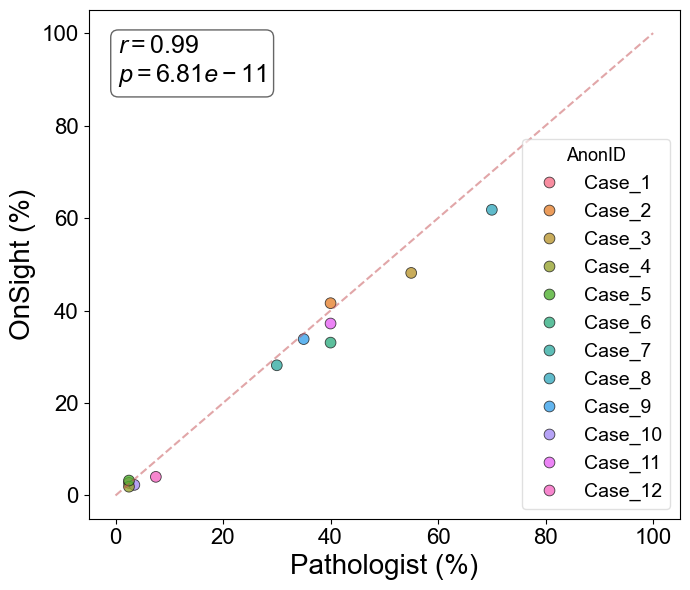

In [9]:
reset_style(rc={"font.weight": "normal", "axes.labelweight": "normal", "mathtext.fontset": "custom",
                "mathtext.rm": "sans", "mathtext.it": "sans:italic", "mathtext.bf": "sans:bold"})
reg = pd.read_csv(MAIN / "fig3" / "3h_ki67_local.csv")
per_case_regions = reg.groupby("SlideID").size()
print(f"{len(reg)} regions from {reg['SlideID'].nunique()} cases; regions per case: "
      f"{per_case_regions.min()}-{per_case_regions.max()}")
unique_ids = reg["SlideID"].unique()
anon_map = {sid: f"Case_{i + 1}" for i, sid in enumerate(unique_ids)}
reg["AnonID"] = reg["SlideID"].map(anon_map)
df = reg.groupby(["SlideID", "AnonID"], as_index=False).mean()
display(df.round(2))
valid_df = df[["Reported", "OnSight"]].dropna()
res = pearson_report(valid_df["Reported"], valid_df["OnSight"], "OnSight vs reported Ki-67 (case means)")
check("3h", "n cases", res["n"], "12")
check("3h", "regions per case (min-max)", f"{per_case_regions.min()}-{per_case_regions.max()}", "10-17")
check("3h", "r", res["r"], "0.994")
check("3h", "df", res["df"], "10")
check("3h", "r 95% CI lower", res["lo"], "0.978")
check("3h", "r 95% CI upper", res["hi"], "0.998")
check("3h", "p", res["p"], "6.81e-11")

plt.figure(figsize=(7, 6))
hue_order = sorted(df["AnonID"].unique(), key=lambda s: int(s.split("_")[1]))
sns.scatterplot(x="Reported", y="OnSight", data=df, hue="AnonID", hue_order=hue_order, s=60, alpha=0.8, edgecolor="k")
plt.plot([0, 100], [0, 100], "r--", alpha=0.5)
plt.xlabel("Pathologist (%)", fontsize=20)
plt.ylabel("OnSight (%)", fontsize=20)
ax = plt.gca()
ax.tick_params(axis="both", which="major", labelsize=16)
plt.text(0.05, 0.95, f"$r = {res['r']:.2f}$\n$p = {res['p']:.2e}$", transform=ax.transAxes, va="top",
         bbox=dict(boxstyle="round", facecolor="white", alpha=0.6), fontsize=18)
plt.legend(title="AnonID", loc="lower right", fontsize=14, title_fontsize=13, frameon=True, framealpha=0.6)
plt.tight_layout()
save(plt.gcf(), "Fig3h")
plt.show()

## Fig 4b

In [10]:
dice = pd.read_csv(MAIN / "fig4" / "4b_ROI_detection_dice_scores.csv")
display(dice)
check("4b", "Dice, deconvolution-based hotspot detection", dice["Deconvolution_based_hotspot_detection_Dice"].item(),
      "0.863", source="submitted panel")
check("4b", "Dice, image-feature-based patch clustering", dice["Image_feature_based_patch_clustering_Dice"].item(),
      "0.806", source="submitted panel")

,Case,Tumor_type,Deconvolution_based_hotspot_detection_Dice,Image_feature_based_patch_clustering_Dice
0,Main_Fig_4b_case,Meningioma,0.863,0.806


## Fig 4c

In [11]:
def norm(s):
    return (s - s.min()) / (s.max() - s.min())

PAIRS = [("1", "2"), ("2", "3"), ("3", "4"), ("1", "3"), ("2", "4"), ("1", "4")]

tcga = pd.read_csv(MAIN / "fig4" / "4c_TCGA_KIRC.csv")
tcga["Grade"] = pd.Categorical(tcga["Grade"].astype(int).astype(str), categories=["1", "2", "3", "4"], ordered=True)
tcga["Circularity"] = norm(1 - tcga["Shape.Circularity_median"])
tcga["Perimeter"] = norm(tcga["Size.Perimeter_median"])
tcga["Intensity"] = norm(tcga["Nucleus.Intensity.IQR_median"])
tcga["Risk_score"] = (tcga["Circularity"] + tcga["Perimeter"] + tcga["Intensity"]) / 3
print("TCGA-KIRC: n =", len(tcga), "| per grade:", tcga["Grade"].value_counts().sort_index().to_dict())
for mine, theirs in [("Circularity", "1-Circularity_Normalized"), ("Perimeter", "Perimeter_Normalized"),
                     ("Intensity", "Intensity_Normalized"), ("Risk_score", "Three_feature_aggregate_score")]:
    print(f"  recomputed {mine:11s} vs Source Data column {theirs:30s}: max |diff| = "
          f"{np.abs(tcga[mine] - tcga[theirs]).max():.1e}")

smh = pd.read_csv(MAIN / "fig4" / "4c_SMH_RCC.csv")
smh["Grade"] = pd.Categorical(smh["Grade"].astype(int).astype(str), categories=["1", "2", "3", "4"], ordered=True)
smh["Circularity"] = norm(1 - smh["Median_nuclear_circularity"])
smh["Perimeter"] = norm(smh["Median_nuclear_perimeter"])
smh["Intensity"] = norm(smh["Median_nuclear_intensity_IQR"])
smh["Risk_score"] = (smh["Circularity"] + smh["Perimeter"] + smh["Intensity"]) / 3
print("SMH: n =", len(smh), "| per grade:", smh["Grade"].value_counts().sort_index().to_dict())
print(f"  recomputed aggregate vs Source Data column: max |diff| = "
      f"{np.abs(smh['Risk_score'] - smh['Three_feature_aggregate_score']).max():.1e}")

for g, n in zip("1234", ["12", "214", "195", "74"]):
    check("4c", f"TCGA-KIRC n G{g}", int((tcga["Grade"] == g).sum()), n)
for g, n in zip("1234", ["7", "10", "9", "8"]):
    check("4c", f"SMH n G{g}", int((smh["Grade"] == g).sum()), n)
check("4c", "TCGA-KIRC n total", len(tcga), "495")
check("4c", "SMH n total", len(smh), "34")

FEATURES = [("TCGA-KIRC", tcga, "Circularity", "Inverse circularity"),
            ("TCGA-KIRC", tcga, "Perimeter", "Perimeter"),
            ("TCGA-KIRC", tcga, "Intensity", "Intensity"),
            ("TCGA-KIRC", tcga, "Risk_score", "Three-feature aggregate score"),
            ("SMH", smh, "Risk_score", "Three-feature aggregate score")]
rows = []
for cohort, d, col, fname in FEATURES:
    for g1, g2 in PAIRS:
        r = welch_stats(d.loc[d["Grade"] == g1, col], d.loc[d["Grade"] == g2, col])
        rows.append({"Cohort": cohort, "Feature": fname, "Comparison": f"G{g1} vs G{g2}", "n1": r["n1"], "n2": r["n2"],
                     "t": r["t"], "df": r["df"], "Exact_P": r["p"], "Hedges_g": r["g"],
                     "Mean_difference": r["mean_difference"], "Mean_difference_CI_95_lower": r["ci_lower"],
                     "Mean_difference_CI_95_upper": r["ci_upper"]})
stats4c = pd.DataFrame(rows)
stats4c.to_csv(OUT / "Fig4c_recomputed_statistics.csv", index=False)
with pd.option_context("display.float_format", "{:.4g}".format):
    display(stats4c)

ref = pd.read_csv(MAIN / "fig4" / "4c_complete_statistics.csv")
num_cols = ["n1", "n2", "t", "df", "Exact_P", "Hedges_g", "Mean_difference", "Mean_difference_CI_95_lower",
            "Mean_difference_CI_95_upper"]
same_keys = (ref[["Cohort", "Feature", "Comparison"]].values == stats4c[["Cohort", "Feature", "Comparison"]].values).all()
rel = (np.abs(stats4c[num_cols].values - ref[num_cols].values) / np.maximum(np.abs(ref[num_cols].values), 1e-300))
print(f"Agreement with 4c_complete_statistics.csv: same 30 comparisons = {same_keys}; "
      f"max relative difference over all {rel.size} values = {rel.max():.1e}")
check("4c", "all 30 rows x 9 statistics agree with 4c_complete_statistics.csv (rel. diff < 1e-6)",
      bool(same_keys and rel.max() < 1e-6), "True", source="Source Data")

legend_p = {("TCGA-KIRC", "Inverse circularity"): ["8.185e-4", "9.360e-4", "4.272e-5", "1.992e-4", "3.384e-9", "9.324e-6"],
            ("TCGA-KIRC", "Perimeter"): ["8.395e-7", "2.618e-6", "4.319e-6", "3.627e-8", "8.913e-12", "1.763e-12"],
            ("TCGA-KIRC", "Intensity"): ["0.03553", "1.295e-6", "0.002986", "4.656e-4", "1.211e-8", "4.240e-6"],
            ("TCGA-KIRC", "Three-feature aggregate score"): ["7.051e-5", "7.138e-9", "1.989e-6", "3.527e-6", "1.396e-13", "9.574e-9"],
            ("SMH", "Three-feature aggregate score"): ["0.01663", "0.003724", "0.4689", "5.130e-5", "5.501e-4", "1.195e-5"]}
for (cohort, fname), plist in legend_p.items():
    sub = stats4c[(stats4c.Cohort == cohort) & (stats4c.Feature == fname)]
    for (_, row), rep in zip(sub.iterrows(), plist):
        check("4c", f"{cohort} {fname} {row.Comparison} Welch p", row.Exact_P, rep)

TCGA-KIRC: n = 495 | per grade: {'1': 12, '2': 214, '3': 195, '4': 74}
  recomputed Circularity vs Source Data column 1-Circularity_Normalized      : max |diff| = 5.0e-10
  recomputed Perimeter   vs Source Data column Perimeter_Normalized          : max |diff| = 5.4e-10
  recomputed Intensity   vs Source Data column Intensity_Normalized          : max |diff| = 5.0e-10
  recomputed Risk_score  vs Source Data column Three_feature_aggregate_score : max |diff| = 5.3e-10
SMH: n = 34 | per grade: {'1': 7, '2': 10, '3': 9, '4': 8}
  recomputed aggregate vs Source Data column: max |diff| = 8.3e-17


,Cohort,Feature,Comparison,n1,n2,t,df,Exact_P,Hedges_g,Mean_difference,Mean_difference_CI_95_lower,Mean_difference_CI_95_upper
0,TCGA-KIRC,Inverse circularity,G1 vs G2,12,214,-4.472,11.66,0.0008185,-1.758,-0.1988,-0.2959,-0.1016
1,TCGA-KIRC,Inverse circularity,G2 vs G3,214,195,-3.334,398.3,0.000936,-0.3303,-0.0375,-0.05961,-0.01539
2,TCGA-KIRC,Inverse circularity,G3 vs G4,195,74,-4.257,114.2,4.272e-05,-0.6267,-0.0773,-0.1133,-0.04133
3,TCGA-KIRC,Inverse circularity,G1 vs G3,12,195,-5.298,11.81,0.0001992,-1.983,-0.2363,-0.3336,-0.1389
4,TCGA-KIRC,Inverse circularity,G2 vs G4,214,74,-6.448,106.6,3.384e-09,-0.9686,-0.1148,-0.1501,-0.0795
5,TCGA-KIRC,Inverse circularity,G1 vs G4,12,74,-6.717,14.14,9.324e-06,-2.212,-0.3136,-0.4136,-0.2135
6,TCGA-KIRC,Perimeter,G1 vs G2,12,214,-8.661,13.18,8.395e-07,-2.025,-0.1808,-0.2259,-0.1358
7,TCGA-KIRC,Perimeter,G2 vs G3,214,195,-4.77,386.2,2.618e-06,-0.4744,-0.04592,-0.06485,-0.02699
8,TCGA-KIRC,Perimeter,G3 vs G4,195,74,-4.841,108.4,4.319e-06,-0.7363,-0.0829,-0.1169,-0.04896
9,TCGA-KIRC,Perimeter,G1 vs G3,12,195,-10.65,14.23,3.627e-08,-2.216,-0.2268,-0.2723,-0.1812


Agreement with 4c_complete_statistics.csv: same 30 comparisons = True; max relative difference over all 270 values = 2.9e-08


[saved] outputs\main\Fig4c_TCGA_inverse_circularity.png and .pdf


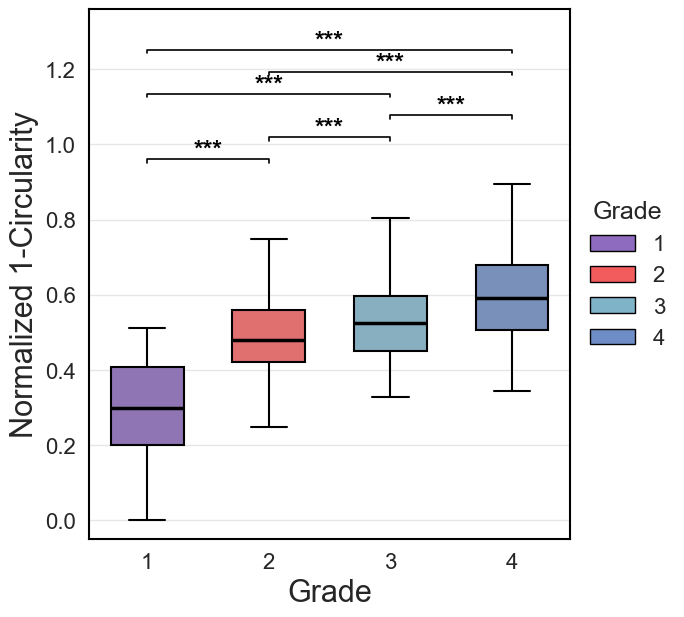

[saved] outputs\main\Fig4c_TCGA_perimeter.png and .pdf


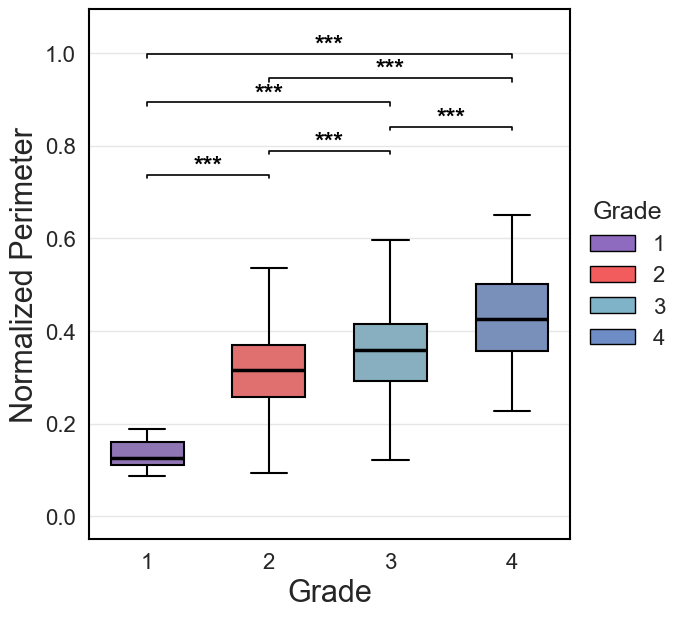

[saved] outputs\main\Fig4c_TCGA_intensity_IQR.png and .pdf


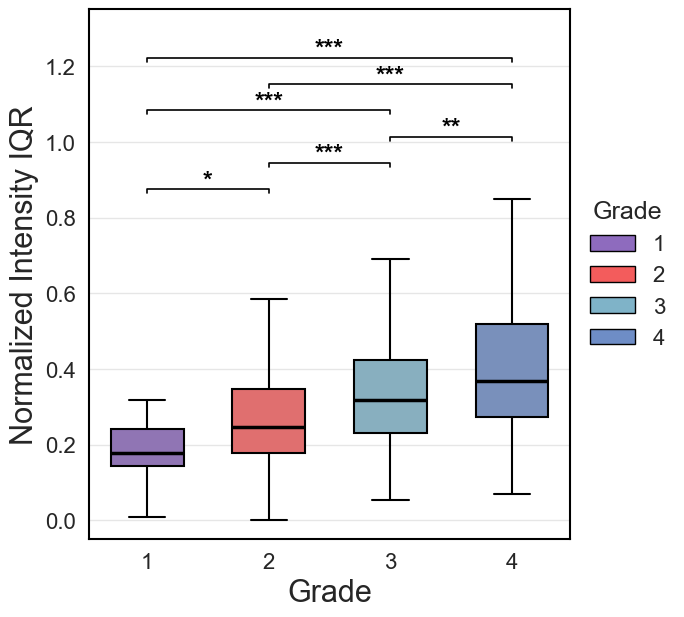

[saved] outputs\main\Fig4c_TCGA_aggregate_score.png and .pdf


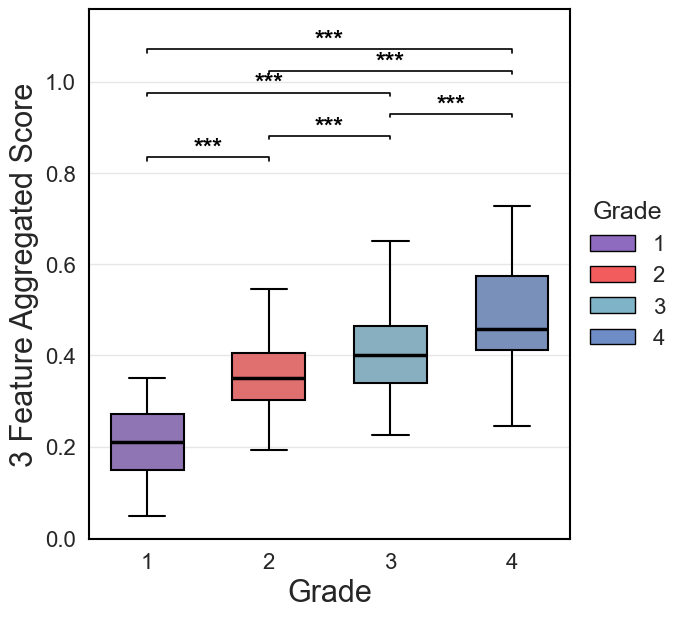

In [12]:
def get_star(p):
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns"

def plot_in_standard_style(df, y_var, y_label, filename):
    colors = ["#8E6BBE", "#F35C5C", "#7FB3C8", "#6E8DC6"]
    grades = ["1", "2", "3", "4"]
    reset_style("whitegrid", rc={"grid.color": ".9"})
    fig, ax = plt.subplots(figsize=(7, 8))
    ax.set_box_aspect(1.1)
    sns.boxplot(data=df, x="Grade", y=y_var, hue="Grade", palette=colors, legend=False, ax=ax, showfliers=False,
                boxprops=dict(edgecolor="black", linewidth=1.5), medianprops=dict(color="black", linewidth=2.5),
                whiskerprops=dict(color="black", linewidth=1.5), capprops=dict(color="black", linewidth=1.5),
                width=0.6, zorder=3)
    ax.set_ylabel(y_label, fontsize=22)
    ax.set_xlabel("Grade", fontsize=22)
    patches = [mpatches.Patch(color=colors[i], label=grades[i], ec="black") for i in range(4)]
    ax.legend(handles=patches, title="Grade", title_fontsize=18, fontsize=16, loc="center left",
              bbox_to_anchor=(1, 0.5), frameon=False)
    whisker_max_list = []
    for g in grades:
        gd = df[df["Grade"] == g][y_var].dropna()
        q1, q3 = gd.quantile(0.25), gd.quantile(0.75)
        whisker_max_list.append(min(gd.max(), q3 + 1.5 * (q3 - q1)))
    y_start = max(whisker_max_list) + df[y_var].std() * 0.1
    v_gap = df[y_var].std() * 0.45
    for tier, (g1, g2) in enumerate(PAIRS):
        p_val = welch_stats(df[df["Grade"] == g1][y_var], df[df["Grade"] == g2][y_var])["p"]
        x1, x2 = grades.index(g1), grades.index(g2)
        y_pos = y_start + tier * v_gap
        tick = v_gap * 0.15
        ax.plot([x1, x1, x2, x2], [y_pos, y_pos + tick, y_pos + tick, y_pos], lw=1.2, c="black", clip_on=False, zorder=5)
        ax.text((x1 + x2) / 2, y_pos + tick * 0.1, get_star(p_val), ha="center", va="bottom", fontsize=18,
                fontweight="bold", color="black")
    for spine in ax.spines.values():
        spine.set_edgecolor("black"); spine.set_linewidth(1.5)
    ax.set_ylim(df[y_var].min() - 0.05, y_pos + v_gap * 2)
    ax.tick_params(axis="both", labelsize=16)
    plt.tight_layout()
    save(fig, filename)
    plt.show()

for var, label, fname in [("Circularity", "Normalized 1-Circularity", "Fig4c_TCGA_inverse_circularity"),
                          ("Perimeter", "Normalized Perimeter", "Fig4c_TCGA_perimeter"),
                          ("Intensity", "Normalized Intensity IQR", "Fig4c_TCGA_intensity_IQR"),
                          ("Risk_score", "3 Feature Aggregated Score", "Fig4c_TCGA_aggregate_score")]:
    plot_in_standard_style(tcga, var, label, fname)

[saved] outputs\main\Fig4c_SMH_aggregate_score.png and .pdf


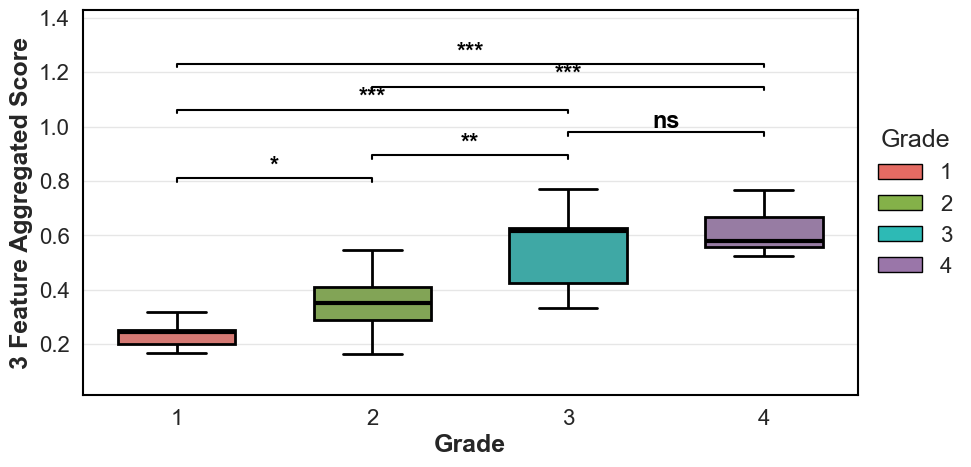

In [13]:
SHOW_POINTS = False
colors = ["#E46B63", "#84B149", "#2DBAB5", "#9A76A9"]
grades = ["1", "2", "3", "4"]
y_var, y_label = "Risk_score", "3 Feature Aggregated Score"
reset_style("whitegrid", rc={"grid.color": ".9"})
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=smh, x="Grade", y=y_var, hue="Grade", palette=colors, legend=False, ax=ax, showfliers=False,
            boxprops=dict(edgecolor="black", linewidth=2.0), medianprops=dict(color="black", linewidth=3.0),
            whiskerprops=dict(color="black", linewidth=2.0), capprops=dict(color="black", linewidth=2.0),
            width=0.6, zorder=3)
if SHOW_POINTS:
    sns.stripplot(data=smh, x="Grade", y=y_var, order=grades, ax=ax, color="white", edgecolor="black", linewidth=0.8,
                  size=6, jitter=0.12, alpha=0.95, zorder=4)
ax.set_ylabel(y_label, fontsize=18, fontweight="bold")
ax.set_xlabel("Grade", fontsize=18, fontweight="bold")
patches = [mpatches.Patch(color=colors[i], label=grades[i], ec="black") for i in range(4)]
ax.legend(handles=patches, title="Grade", title_fontsize=18, fontsize=16, loc="center left", bbox_to_anchor=(1, 0.5),
          frameon=False)
whisker_max_list = []
for g in grades:
    gd = smh[smh["Grade"] == g][y_var].dropna()
    q1, q3 = gd.quantile(0.25), gd.quantile(0.75)
    whisker_max_list.append(min(gd.max(), q3 + 1.5 * (q3 - q1)))
y_start = max(whisker_max_list) + smh[y_var].std() * 0.15
v_gap = smh[y_var].std() * 0.45
for tier, (g1, g2) in enumerate(PAIRS):
    p_val = welch_stats(smh[smh["Grade"] == g1][y_var], smh[smh["Grade"] == g2][y_var])["p"]
    x1, x2 = grades.index(g1), grades.index(g2)
    y_pos = y_start + tier * v_gap
    tick = v_gap * 0.15
    ax.plot([x1, x1, x2, x2], [y_pos, y_pos + tick, y_pos + tick, y_pos], lw=1.5, c="black", clip_on=False, zorder=5)
    ax.text((x1 + x2) / 2, y_pos + tick / 0.98, get_star(p_val), ha="center", va="bottom", fontsize=17,
            fontweight="bold", color="black")
for spine in ax.spines.values():
    spine.set_edgecolor("black"); spine.set_linewidth(1.5); spine.set_visible(True)
ax.set_ylim(smh[y_var].min() - 0.05, y_pos + v_gap * 2.5)
ax.tick_params(axis="both", labelsize=16)
save(fig, "Fig4c_SMH_aggregate_score")
plt.show()

## Fig 5a

G2 n = 71 (2 deaths); G3 n = 64 (10 deaths)
two-sided log-rank: chi2(1) = 7.0392, p = 0.007975


[saved] outputs\main\Fig5a.png and .pdf


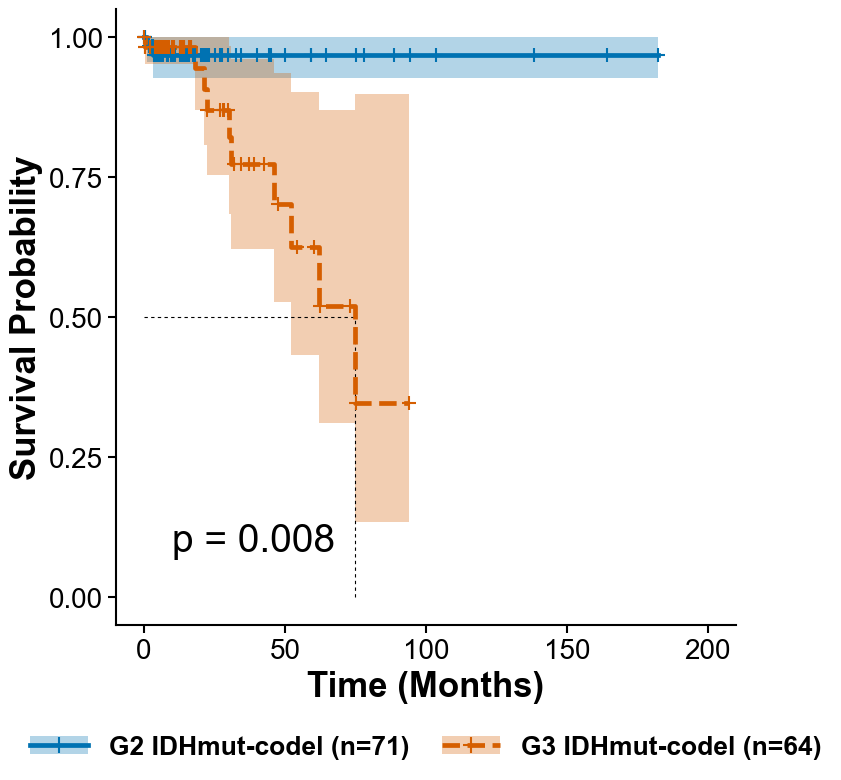

In [14]:
reset_style()
lgg = pd.read_csv(MAIN / "fig5" / "5a_TCGA_G2G3_LGG_Survival.csv")
lgg = lgg[lgg["GRADE"].isin(["G2", "G3"]) & (lgg["SUBTYPE"] == "IDHmut-codel") & (lgg["OS_MONTHS"] > 0)]
g2, g3 = lgg[lgg["GRADE"] == "G2"], lgg[lgg["GRADE"] == "G3"]
lr = logrank_test(g2["OS_MONTHS"], g3["OS_MONTHS"], event_observed_A=g2["os.status"], event_observed_B=g3["os.status"])
print(f"G2 n = {len(g2)} ({int(g2['os.status'].sum())} deaths); G3 n = {len(g3)} ({int(g3['os.status'].sum())} deaths)")
print(f"two-sided log-rank: chi2({lr.degrees_of_freedom}) = {lr.test_statistic:.4f}, p = {lr.p_value:.4g}")
check("5a", "G2 n", len(g2), "71"); check("5a", "G3 n", len(g3), "64")
check("5a", "log-rank chi2", lr.test_statistic, "7.04"); check("5a", "log-rank df", lr.degrees_of_freedom, "1")
check("5a", "log-rank p", lr.p_value, "0.0080")
check("5a", "p label on panel", survminer_p_label(lr.p_value), "p = 0.008", source="submitted panel")
fig, ax = ggsurvplot_like(
    [dict(label=f"G2 IDHmut-codel (n={len(g2)})", T=g2["OS_MONTHS"], E=g2["os.status"], color="#0072B2", ls="-"),
     dict(label=f"G3 IDHmut-codel (n={len(g3)})", T=g3["OS_MONTHS"], E=g3["os.status"], color="#D55E00", ls="--")],
    survminer_p_label(lr.p_value))
save(fig, "Fig5a")
plt.show()

## Fig 5b

n = 64 (high 36, low 28); deaths = 10 (high 10, low 0)
two-sided log-rank: chi2(1) = 8.4782, p = 0.003594


[saved] outputs\main\Fig5b.png and .pdf


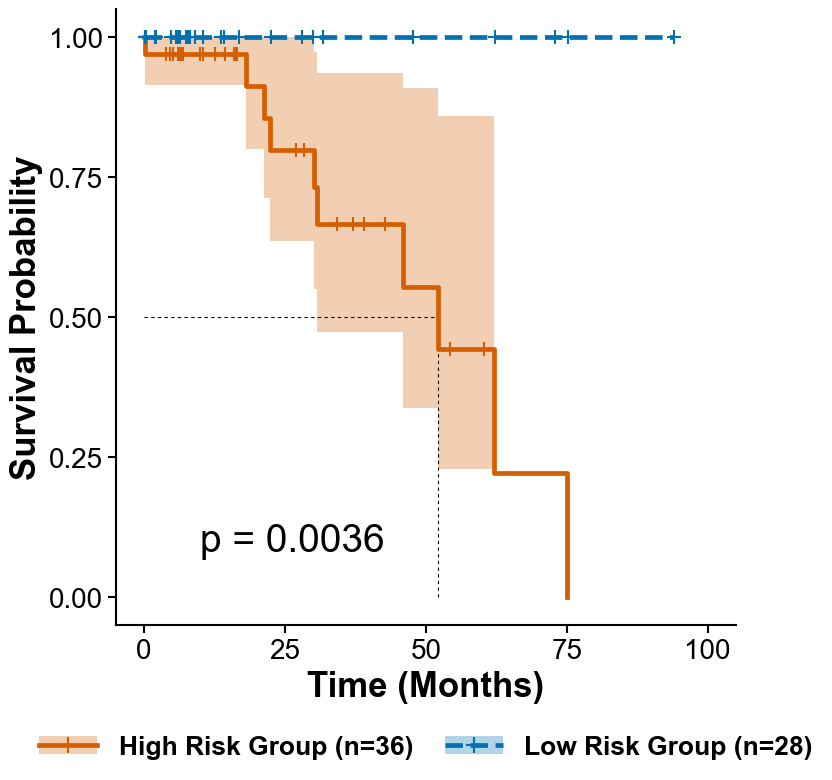

In [15]:
reset_style()
ol = pd.read_csv(MAIN / "fig5" / "5b_Oligos_G3_survival_with_LOOCV_predictions.csv")
hi, lo = ol[ol["group"] == "high"], ol[ol["group"] == "low"]
lr = logrank_test(hi["os_months"], lo["os_months"], event_observed_A=hi["os_event"], event_observed_B=lo["os_event"])
print(f"n = {len(ol)} (high {len(hi)}, low {len(lo)}); deaths = {int(ol['os_event'].sum())} "
      f"(high {int(hi['os_event'].sum())}, low {int(lo['os_event'].sum())})")
print(f"two-sided log-rank: chi2({lr.degrees_of_freedom}) = {lr.test_statistic:.4f}, p = {lr.p_value:.4g}")
check("5b", "n", len(ol), "64"); check("5b", "high-risk n", len(hi), "36"); check("5b", "low-risk n", len(lo), "28")
check("5b", "deaths", int(ol["os_event"].sum()), "10", source="brief")
check("5b", "log-rank chi2", lr.test_statistic, "8.48"); check("5b", "log-rank df", lr.degrees_of_freedom, "1")
check("5b", "log-rank p", lr.p_value, "0.0036")
fig, ax = ggsurvplot_like(
    [dict(label=f"High Risk Group (n={len(hi)})", T=hi["os_months"], E=hi["os_event"], color="#D55E00", ls="-"),
     dict(label=f"Low Risk Group (n={len(lo)})", T=lo["os_months"], E=lo["os_event"], color="#0072B2", ls="--")],
    survminer_p_label(lr.p_value))
save(fig, "Fig5b")
plt.show()

## Fig 5c

5c: top 6 of 15 features (mean gain)


,Feature,AverageGain
0,Nucleus.Intensity.Mean_median,0.503104
1,Shape.Solidity_median,0.294654
2,Nucleus.Intensity.Std_median,0.046966
3,Nucleus.Intensity.HistEntropy_median,0.040220
4,Shape.Eccentricity_median,0.034982
5,Nucleus.Intensity.IQR_median,0.019038


[saved] outputs\main\Fig5c.png and .pdf


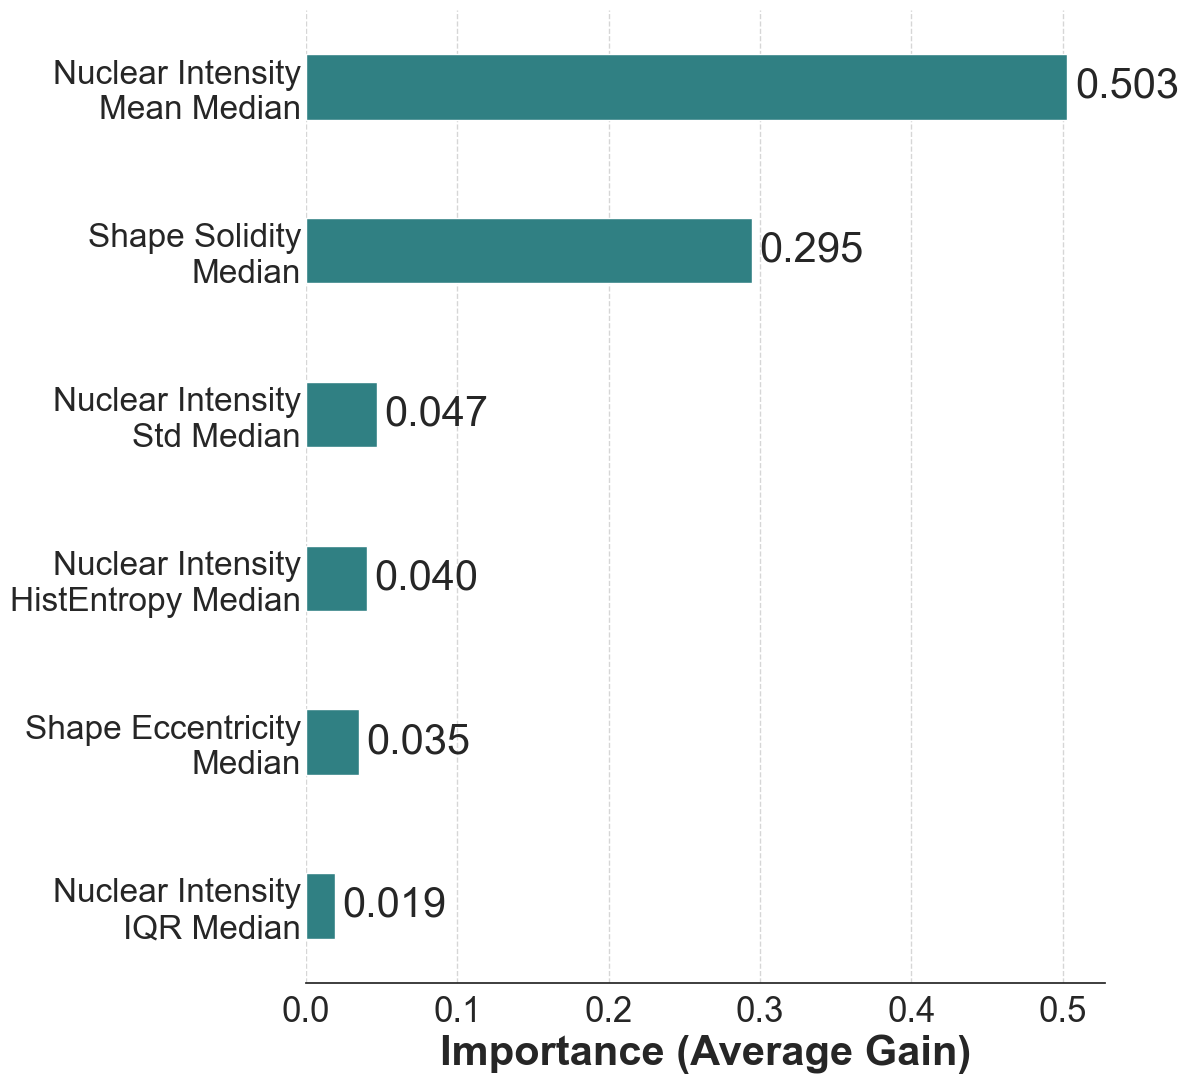

In [16]:
PRETTY = {"Nucleus.Intensity.Mean_median": "Nuclear Intensity\nMean Median", "Shape.Solidity_median": "Shape Solidity\nMedian",
          "Nucleus.Intensity.Std_median": "Nuclear Intensity\nStd Median",
          "Nucleus.Intensity.HistEntropy_median": "Nuclear Intensity\nHistEntropy Median",
          "Shape.Eccentricity_median": "Shape Eccentricity\nMedian", "Nucleus.Intensity.IQR_median": "Nuclear Intensity\nIQR Median",
          "cellularity_density": "Cellularity", "Shape.Circularity_median": "Shape Circularity\nMedian",
          "Size.Perimeter_median": "Size Perimeter\nMedian"}

def plot_importance(path, name, panel, expected, xticks=None, top_n=6):
    reset_style("white")
    df = pd.read_csv(path)
    top = df.sort_values("AverageGain", ascending=False).head(top_n).reset_index(drop=True)
    print(f"{panel}: top {top_n} of {len(df)} features (mean gain)")
    display(top)
    for (_, row), (feat, val) in zip(top.iterrows(), expected):
        check(panel, f"importance rank {_ + 1}: {feat}", row.AverageGain, val, source="submitted panel")
        assert row.Feature == feat, (row.Feature, feat)
    d = top.sort_values("AverageGain", ascending=True).reset_index(drop=True)
    fig = plt.figure(figsize=(12, 11))
    plt.barh(np.arange(len(d)), d["AverageGain"], color="#308083", height=0.4)
    for i, v in enumerate(d["AverageGain"]):
        plt.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=30)
    plt.xlabel("Importance (Average Gain)", fontsize=30, fontweight="bold")
    plt.ylabel("")
    ax = plt.gca()
    ax.grid(axis="x", linestyle="--", linewidth=1, alpha=0.8)
    ax.set_axisbelow(True)
    sns.despine(left=True, bottom=False)
    plt.xticks(fontsize=25)
    if xticks is not None:
        plt.xticks(xticks, fontsize=25)
    plt.yticks(np.arange(len(d)), [PRETTY.get(f, f) for f in d["Feature"]], fontsize=24)
    ax.tick_params(axis="y", length=0)
    plt.tight_layout()
    save(fig, name)
    plt.show()

plot_importance(MAIN / "fig5" / "5c_xgboost_feature_importance_oligos.csv", "Fig5c", "5c",
                [("Nucleus.Intensity.Mean_median", "0.503"), ("Shape.Solidity_median", "0.295"),
                 ("Nucleus.Intensity.Std_median", "0.047"), ("Nucleus.Intensity.HistEntropy_median", "0.040"),
                 ("Shape.Eccentricity_median", "0.035"), ("Nucleus.Intensity.IQR_median", "0.019")])

## Fig 5d

2000 simulations; levels = 20 (20 to 1 patches); iterations per level = [100]; patients = [64]; events = [10]; feature = Nucleus.Intensity.Mean_median


,Num_Patches,Mean_P_Value,Median_P_Value,P_Value_25,P_Value_75,N_Valid_Iters
0,20,0.000305,0.000305,0.000305,0.000305,100
1,19,0.000278,0.000305,0.000227,0.000305,100
2,18,0.000316,0.000305,0.000227,0.000305,100
3,17,0.000388,0.000305,0.000227,0.000305,100
4,16,0.000317,0.000305,0.000227,0.000305,100
5,15,0.000428,0.000305,0.000227,0.000305,100
6,14,0.000479,0.000305,0.000227,0.00032,100
7,13,0.000535,0.000305,0.000227,0.00032,100
8,12,0.00057,0.000305,0.000227,0.00032,100
9,11,0.000594,0.000305,0.000227,0.000374,100


[saved] outputs\main\Fig5d.png and .pdf


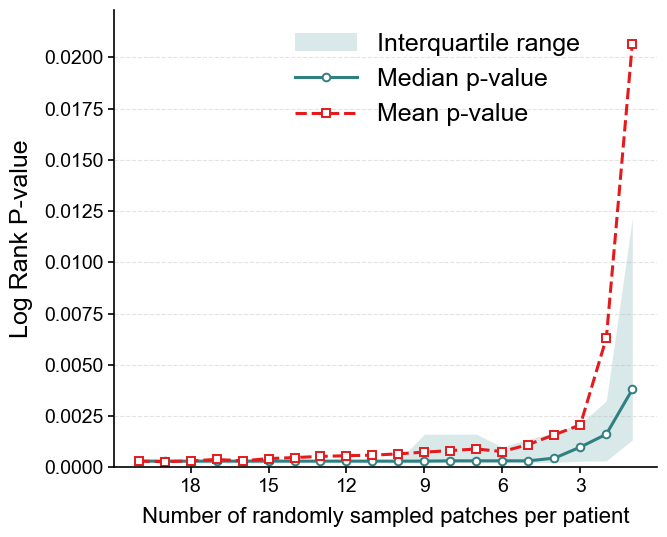

In [17]:
reset_style(rc={"font.family": "Arial", "font.size": 11, "axes.linewidth": 1.2, "xtick.major.width": 1.2,
                "ytick.major.width": 1.2, "xtick.major.size": 4, "ytick.major.size": 4})
sim = pd.read_csv(MAIN / "fig5" / "5d_patch_dilution.csv")
print(f"{len(sim)} simulations; levels = {sim['Num_Patches'].nunique()} ({sim['Num_Patches'].max()} to "
      f"{sim['Num_Patches'].min()} patches); iterations per level = {sorted(sim.groupby('Num_Patches').size().unique())}; "
      f"patients = {sorted(sim['N_Patients'].unique())}; events = {sorted(sim['N_Events'].unique())}; "
      f"feature = {sim['Feature'].unique()[0]}")
df_results = (sim.groupby("Num_Patches")["Logrank_P_Value"]
                 .agg(Mean_P_Value="mean", Median_P_Value="median",
                      P_Value_25=lambda v: np.percentile(v, 25), P_Value_75=lambda v: np.percentile(v, 75),
                      N_Valid_Iters="count")
                 .reset_index().sort_values("Num_Patches", ascending=False))
with pd.option_context("display.float_format", "{:.3g}".format):
    display(df_results.reset_index(drop=True))
check("5d", "simulations per level x levels", f"{sim.groupby('Num_Patches').size().unique()[0]}x{sim['Num_Patches'].nunique()}",
      "100x20")
check("5d", "patients per simulation", int(sim["N_Patients"].unique()[0]), "64")

x = df_results["Num_Patches"].values
y_median, y_mean = df_results["Median_P_Value"].values, df_results["Mean_P_Value"].values
q25, q75 = df_results["P_Value_25"].values, df_results["P_Value_75"].values
fig, ax = plt.subplots(figsize=(6.8, 5.5))
ax.fill_between(x, q25, q75, color="#308083", alpha=0.18, linewidth=0, label="Interquartile range")
ax.plot(x, y_median, color="#308083", linewidth=2.2, marker="o", markersize=5.5, markerfacecolor="white",
        markeredgewidth=1.4, label="Median p-value")
ax.plot(x, y_mean, color="#E41A1C", linewidth=2.2, linestyle="--", marker="s", markersize=5.5, markerfacecolor="white",
        markeredgewidth=1.4, label="Mean p-value")
ax.invert_xaxis()
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel("Number of randomly sampled patches per patient", labelpad=8, fontsize=16)
ax.set_ylabel("Log Rank P-value", labelpad=8, fontsize=18)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", linestyle="--", linewidth=0.8, alpha=0.35)
ax.grid(axis="x", visible=False)
ax.set_ylim(0, max(np.max(q75), np.max(y_mean)) * 1.08)
ax.legend(frameon=False, loc="upper right", bbox_to_anchor=(0.9, 1.0), fontsize=18, handlelength=2.5)
ax.tick_params(axis="both", which="major", labelsize=14)
plt.tight_layout()
save(fig, "Fig5d")
plt.show()

## Fig 5e

n = 478; per grade: {'Grade 2': 211, 'Grade 3': 194, 'Grade 4': 73}; deaths: {'Grade 2': 36, 'Grade 3': 64, 'Grade 4': 52}
overall log-rank: chi2(2) = 74.9567, p = 5.289e-17


[saved] outputs\main\Fig5e.png and .pdf


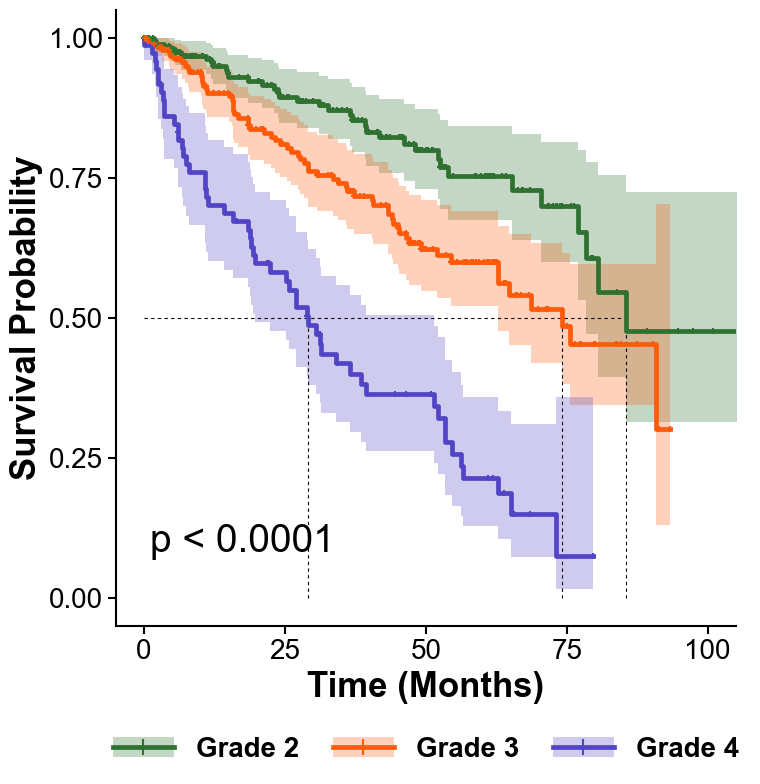

In [18]:
reset_style()
kg = pd.read_csv(MAIN / "fig5" / "5e_TCGA_G2G3G4_KIRC_survival.csv")
kg = kg[kg["os_months"].notna() & kg["os_event"].notna() & kg["grade"].notna() & (kg["os_months"] > 0)]
order = ["Grade 2", "Grade 3", "Grade 4"]
mlr = multivariate_logrank_test(kg["os_months"], kg["grade"], kg["os_event"])
counts = kg["grade"].value_counts().reindex(order)
print(f"n = {len(kg)}; per grade: {counts.to_dict()}; deaths: {kg.groupby('grade')['os_event'].sum().reindex(order).to_dict()}")
print(f"overall log-rank: chi2({mlr.degrees_of_freedom}) = {mlr.test_statistic:.4f}, p = {mlr.p_value:.4g}")
check("5e", "n", len(kg), "478")
for g, n in zip(order, ["211", "194", "73"]):
    check("5e", f"{g} n", int(counts[g]), n)
check("5e", "overall log-rank chi2", mlr.test_statistic, "74.96"); check("5e", "log-rank df", mlr.degrees_of_freedom, "2")
check("5e", "overall log-rank p", mlr.p_value, "5.29e-17")
cols = {"Grade 2": "#2E7131", "Grade 3": "#FF5A0A", "Grade 4": "#5145C6"}
fig, ax = ggsurvplot_like(
    [dict(label=g, T=kg.loc[kg.grade == g, "os_months"], E=kg.loc[kg.grade == g, "os_event"], color=cols[g], ls="-")
     for g in order],
    survminer_p_label(mlr.p_value), p_xy=(1, 0.10), conf_alpha=0.28, censor_ms=5, legend_fs=20)
save(fig, "Fig5e")
plt.show()

## Fig 5f, 5g

5f: n = 194 (high 131, low 63); deaths = 64; two-sided log-rank chi2(1) = 6.1810, p = 0.01291


[saved] outputs\main\Fig5f.png and .pdf


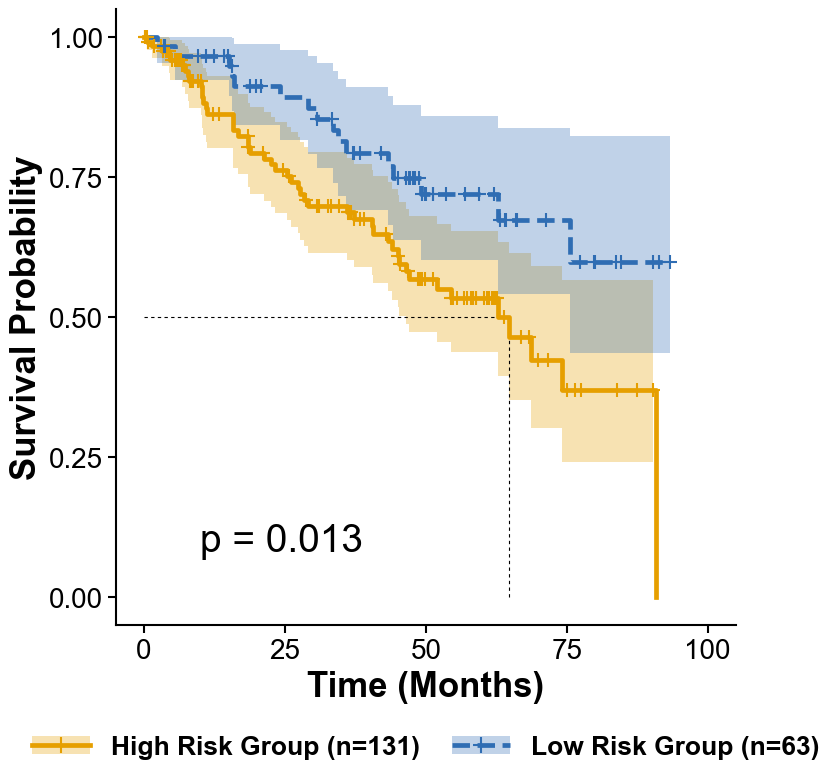

5g: n = 211 (high 120, low 91); deaths = 36; two-sided log-rank chi2(1) = 6.5742, p = 0.01035


[saved] outputs\main\Fig5g.png and .pdf


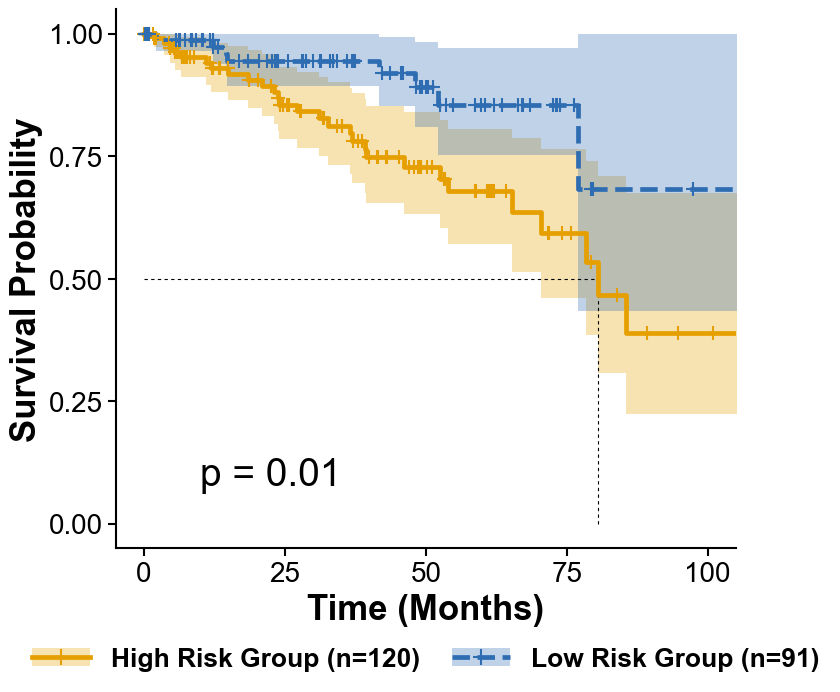

In [19]:
def risk_group_km(path, name, panel, exp, figsize=(8, 8)):
    reset_style()
    d = pd.read_csv(path)
    hi, lo = d[d["group"] == "high"], d[d["group"] == "low"]
    lr = logrank_test(hi["os_months"], lo["os_months"], event_observed_A=hi["os_event"], event_observed_B=lo["os_event"])
    print(f"{panel}: n = {len(d)} (high {len(hi)}, low {len(lo)}); deaths = {int(d['os_event'].sum())}; "
          f"two-sided log-rank chi2({lr.degrees_of_freedom}) = {lr.test_statistic:.4f}, p = {lr.p_value:.4g}")
    check(panel, "n", len(d), exp["n"]); check(panel, "high-risk n", len(hi), exp["high"], source="brief/panel")
    check(panel, "low-risk n", len(lo), exp["low"], source="brief/panel")
    check(panel, "log-rank chi2", lr.test_statistic, exp["chi2"]); check(panel, "log-rank df", lr.degrees_of_freedom, "1")
    check(panel, "log-rank p", lr.p_value, exp["p"])
    fig, ax = ggsurvplot_like(
        [dict(label=f"High Risk Group (n={len(hi)})", T=hi["os_months"], E=hi["os_event"], color="#E69F00", ls="-"),
         dict(label=f"Low Risk Group (n={len(lo)})", T=lo["os_months"], E=lo["os_event"], color="#2F6DB3", ls="--")],
        survminer_p_label(lr.p_value), figsize=figsize)
    save(fig, name)
    plt.show()

risk_group_km(MAIN / "fig5" / "5f_KIRC_G3_survival_with_LOOCV_predictions.csv", "Fig5f", "5f",
              dict(n="194", high="131", low="63", chi2="6.18", p="0.0129"))
risk_group_km(MAIN / "fig5" / "5g_KIRC_G2_survival_with_LOOCV_predictions.csv", "Fig5g", "5g",
              dict(n="211", high="120", low="91", chi2="6.57", p="0.0103"), figsize=(8, 7))

## Fig 5h

5h: top 6 of 15 features (mean gain)


,Feature,AverageGain
0,cellularity_density,0.176356
1,Nucleus.Intensity.Mean_median,0.138223
2,Nucleus.Intensity.HistEntropy_median,0.104335
3,Shape.Circularity_median,0.079486
4,Shape.Solidity_median,0.075378
5,Size.Perimeter_median,0.064413


[saved] outputs\main\Fig5h.png and .pdf


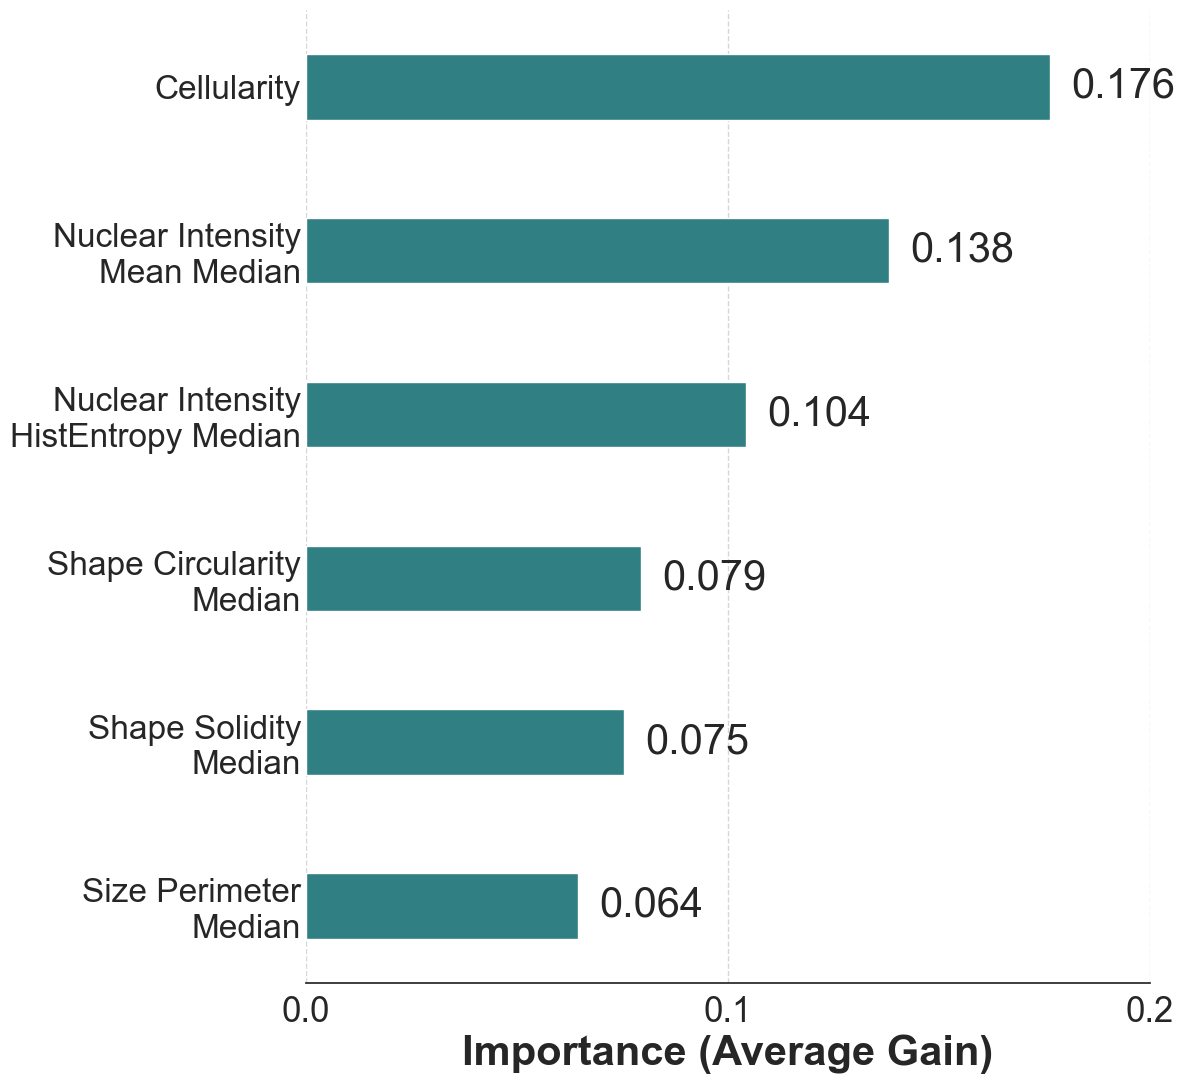

In [20]:
plot_importance(MAIN / "fig5" / "5h_xgboost_feature_importance_rcc.csv", "Fig5h", "5h",
                [("cellularity_density", "0.176"), ("Nucleus.Intensity.Mean_median", "0.138"),
                 ("Nucleus.Intensity.HistEntropy_median", "0.104"), ("Shape.Circularity_median", "0.079"),
                 ("Shape.Solidity_median", "0.075"), ("Size.Perimeter_median", "0.064")], xticks=[0, 0.1, 0.2])

## Fig 5i

n = 701 cells: tumour = 420, lymphocyte = 281


[saved] outputs\main\Fig5i.png and .pdf


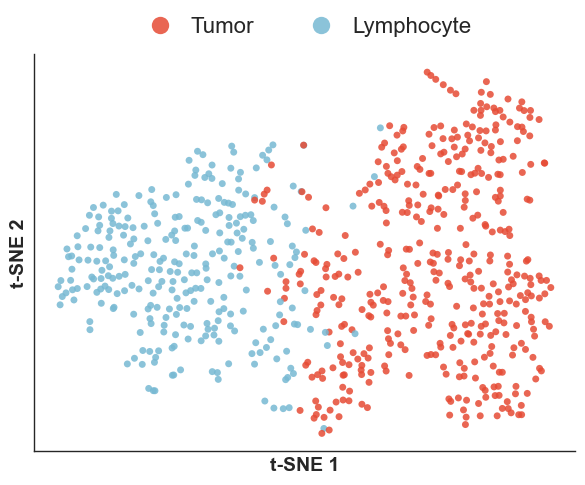

In [21]:
reset_style("ticks", "paper", font_scale=1.2)
he = pd.read_csv(MAIN / "fig5" / "5i_Subgrouping_HE.csv")
label_map = {0: "Tumor", 1: "Lymphocyte"}
he["Cell_Type_check"] = he["Cluster"].map(label_map)
assert (he["Cell_Type_check"] == he["Cell_Type"]).all()
counts = he["Cell_Type"].value_counts()
print(f"n = {len(he)} cells: tumour = {counts['Tumor']}, lymphocyte = {counts['Lymphocyte']}")
check("5i", "n cells", len(he), "701"); check("5i", "tumour cells", int(counts["Tumor"]), "420")
check("5i", "lymphocytes", int(counts["Lymphocyte"]), "281")

palette = {"Tumor": "#E64B35", "Lymphocyte": "#77B9D3"}
fig, ax = plt.subplots(figsize=(6, 5))
sns.scatterplot(x="tSNE_1", y="tSNE_2", hue="Cell_Type", hue_order=["Tumor", "Lymphocyte"], palette=palette, data=he, s=25,
                alpha=0.85, linewidth=0, ax=ax)
ax.set_xlabel("t-SNE 1", fontweight="bold", fontsize=14)
ax.set_ylabel("t-SNE 2", fontweight="bold", fontsize=14)
ax.tick_params(axis="both", which="both", bottom=False, left=False, labelbottom=False, labelleft=False)
ax.legend(frameon=False, borderpad=0.3, handletextpad=0.4, fontsize=16, markerscale=2.5, title=None,
          loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)
sns.despine(ax=ax)
plt.tight_layout()
save(fig, "Fig5i")
plt.show()

## Fig 5j

Standard: 81/1686 = 4.80%
Filtered (lymphocytes removed by size): 70/867 = 8.07%
Pathologist: 8-10% (plotted at 9%)


[saved] outputs\main\Fig5j.png and .pdf


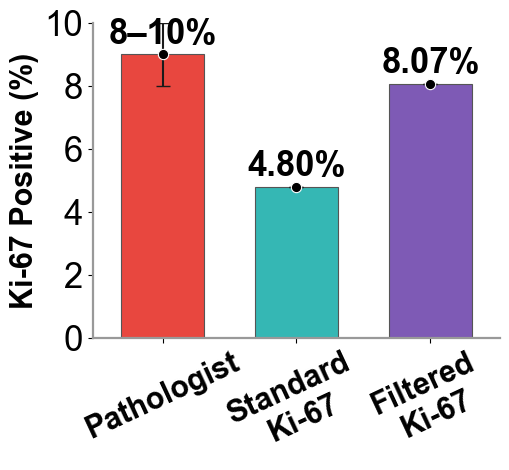

In [22]:
reset_style()
kj = pd.read_csv(MAIN / "fig5" / "5j_Subgrouping_Ki67.csv").set_index("Method")
std_pct = 100 * kj.loc["Standard", "Positive_cell_number"] / kj.loc["Standard", "Total_cell_number"]
fil_pct = 100 * kj.loc["Filtered", "Positive_cell_number"] / kj.loc["Filtered", "Total_cell_number"]
pl, pu = kj.loc["Pathologist", "Ki67_percent_lower"], kj.loc["Pathologist", "Ki67_percent_upper"]
print(f"Standard: {int(kj.loc['Standard', 'Positive_cell_number'])}/{int(kj.loc['Standard', 'Total_cell_number'])} = {std_pct:.2f}%")
print(f"Filtered (lymphocytes removed by size): {int(kj.loc['Filtered', 'Positive_cell_number'])}/"
      f"{int(kj.loc['Filtered', 'Total_cell_number'])} = {fil_pct:.2f}%")
print(f"Pathologist: {pl:.0f}-{pu:.0f}% (plotted at {(pl + pu) / 2:.0f}%)")
check("5j", "standard Ki-67 (%)", std_pct, "4.80", source="submitted panel")
check("5j", "filtered Ki-67 (%)", fil_pct, "8.07", source="submitted panel")
check("5j", "pathologist range (%)", f"{pl:.0f}-{pu:.0f}", "8-10")

labels = ["Pathologist", "Standard\nKi-67", "Filtered\nKi-67"]
values = [(pl + pu) / 2, std_pct, fil_pct]
colors = ["#E8473F", "#35B7B4", "#7E5AB5"]
yerr = [[(pu - pl) / 2, 0, 0], [(pu - pl) / 2, 0, 0]]
fig, ax = plt.subplots(figsize=(5.2, 4.8))
bars = ax.bar(labels, values, yerr=yerr, capsize=5, color=colors, width=0.62, edgecolor="#555555", linewidth=0.8)
ax.scatter([b.get_x() + b.get_width() / 2 for b in bars], values, s=55, color="black", edgecolor="white", linewidth=0.8,
           zorder=5)
ax.set_ylim(0, 10)
ax.set_yticks(range(0, 11, 2))
ax.set_ylabel("Ki-67 Positive (%)", fontsize=22, fontweight="bold")
ax.tick_params(axis="y", labelsize=25)
for tick in ax.get_xticklabels():
    tick.set_fontweight("bold")
for bar, txt in zip(bars, [f"{pl:.0f}–{pu:.0f}%", f"{std_pct:.2f}%", f"{fil_pct:.2f}%"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.1, txt, ha="center", va="bottom", fontsize=25,
            fontweight="bold")
ax.tick_params(axis="x", labelsize=22, labelrotation=25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_linewidth(1.6); ax.spines[side].set_color("#999999")
ax.grid(False)
ax.margins(x=0.08)
plt.tight_layout()
save(fig, "Fig5j")
plt.show()

## Fig 5k

Type 1 n = 236, mean = 1457.91 µm² (SD 662.47); Type 2 n = 270, mean = 715.84 µm² (SD 586.27)
K-S: D = 0.6109, p = 1.996e-44
Welch: t(473.16) = 13.2584, p = 2.435e-34, Hedges' g = 1.189; mean difference (type 1 - type 2) = 742.07 µm², 95% CI [632.09, 852.05]


[saved] outputs\main\Fig5k.png and .pdf


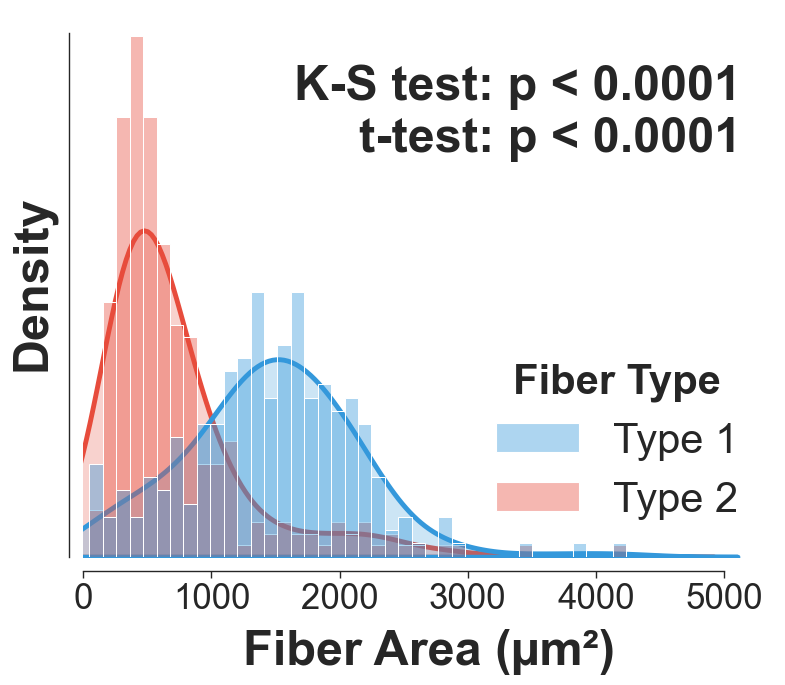

In [23]:
reset_style("ticks", "paper", font_scale=1.2)
mf = pd.read_csv(MAIN / "fig5" / "5k_Subgrouping_Muscle_Fiber_Atrophy.csv").dropna(subset=["Cluster"])
unique_clusters = sorted(mf["Cluster"].astype(int).unique())
cluster_map = {unique_clusters[0]: "Type 1", unique_clusters[1]: "Type 2"}
assert (mf["Cluster"].astype(int).map(cluster_map) == mf["Fiber Type"]).all()
df_plot = mf[mf["Condition"] == "Atrophy"].copy()
area_t1 = df_plot.loc[df_plot["Fiber Type"] == "Type 1", "Area"].dropna()
area_t2 = df_plot.loc[df_plot["Fiber Type"] == "Type 2", "Area"].dropna()
ks = stats.ks_2samp(area_t1, area_t2, alternative="two-sided", method="auto")
w = welch_stats(area_t1, area_t2)
print(f"Type 1 n = {len(area_t1)}, mean = {area_t1.mean():.2f} µm² (SD {area_t1.std():.2f}); "
      f"Type 2 n = {len(area_t2)}, mean = {area_t2.mean():.2f} µm² (SD {area_t2.std():.2f})")
print(f"K-S: D = {ks.statistic:.4f}, p = {ks.pvalue:.3e}")
print(f"Welch: t({w['df']:.2f}) = {w['t']:.4f}, p = {w['p']:.3e}, Hedges' g = {w['g']:.3f}; mean difference "
      f"(type 1 - type 2) = {w['mean_difference']:.2f} µm², 95% CI [{w['ci_lower']:.2f}, {w['ci_upper']:.2f}]")
check("5k", "Type 1 n", len(area_t1), "236"); check("5k", "Type 2 n", len(area_t2), "270")
check("5k", "K-S D", ks.statistic, "0.611"); check("5k", "K-S p", ks.pvalue, "2.00e-44")
check("5k", "Welch df", w["df"], "473.16"); check("5k", "Welch t", w["t"], "13.26"); check("5k", "Welch p", w["p"], "2.43e-34")
check("5k", "Hedges g", w["g"], "1.19"); check("5k", "mean difference (µm²)", w["mean_difference"], "742.07")
check("5k", "mean difference 95% CI lower", w["ci_lower"], "632.09")
check("5k", "mean difference 95% CI upper", w["ci_upper"], "852.05")

def format_p(p):
    return "p < 0.0001" if p < 0.0001 else f"p = {p:.4f}"

plt.figure(figsize=(8, 7))
palette = {"Type 1": "#3498db", "Type 2": "#e74c3c"}
hue_order = ["Type 1", "Type 2"]
ax = sns.kdeplot(data=df_plot, x="Area", hue="Fiber Type", hue_order=hue_order, palette=palette, fill=True, alpha=0.25,
                 linewidth=3.5, common_norm=False, bw_adjust=1.3)
sns.histplot(data=df_plot, x="Area", hue="Fiber Type", hue_order=hue_order, palette=palette, bins=40, stat="density",
             common_norm=False, alpha=0.4)
plt.xlim(left=0)
ax.text(0.95, 0.9, f"K-S test: {format_p(ks.pvalue)}\nt-test: {format_p(w['p'])}", transform=ax.transAxes, ha="right",
        va="top", fontsize=35, fontweight="bold", bbox=dict(facecolor="white", alpha=0.5, edgecolor="none"))
sns.despine(offset=10, trim=True)
plt.xlabel("Fiber Area (µm²)", fontweight="bold", labelpad=10, fontsize=35)
plt.ylabel("Density", fontweight="bold", labelpad=10, fontsize=35)
plt.yticks([])
ax.tick_params(axis="x", which="major", labelsize=25)
if ax.get_legend() is not None:
    legend = ax.get_legend()
    legend.set_title("Fiber Type")
    legend.set_frame_on(False)
    plt.setp(legend.get_title(), fontsize=35, fontweight="bold")
    plt.setp(legend.get_texts(), fontsize=35, fontweight="bold")
sns.move_legend(ax, "lower right", title="Fiber Type", frameon=False, fontsize=30, title_fontsize=30)
plt.tight_layout()
save(plt.gcf(), "Fig5k")
plt.show()

## Fig 6c

6c ROC file identical to CM file: True
InDist counts: {1: 1409, 0: 211}
in-distribution n = 1409 | per class: {'Epithelial pattern': 47, 'Glial histology': 943, 'Meningothelial Histology': 344, 'Schwannian histology': 75}


,class,AUC
0,Epithelial pattern,0.9728
1,Glial histology,0.9962
2,Meningothelial Histology,0.9962
3,Schwannian histology,0.9974


[saved] outputs\main\Fig6c_ROC.png and .pdf


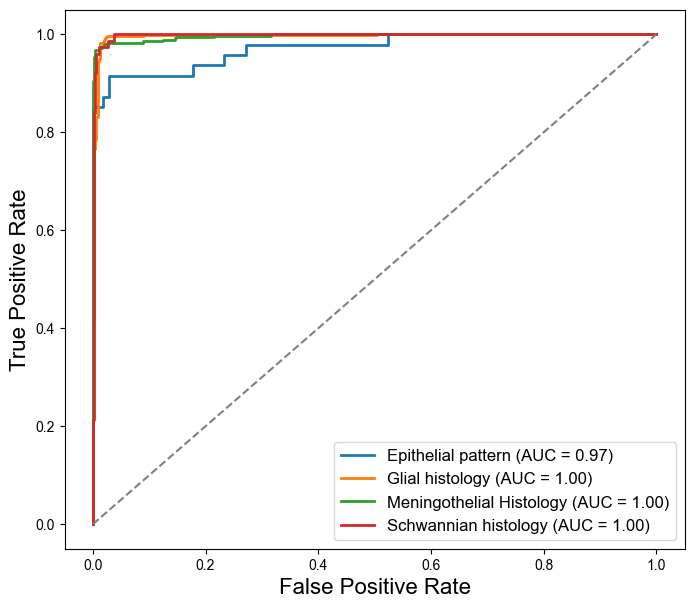

                 pred Epithelial  pred Glial  pred Meningioma  pred Schwannian
true Epithelial               40           6                0                1
true Glial                     0         940                2                1
true Meningioma                3           6              333                2
true Schwannian                0           6                6               63
accuracy = 1376/1409 = 0.9766


[saved] outputs\main\Fig6c_confusion_matrix.png and .pdf


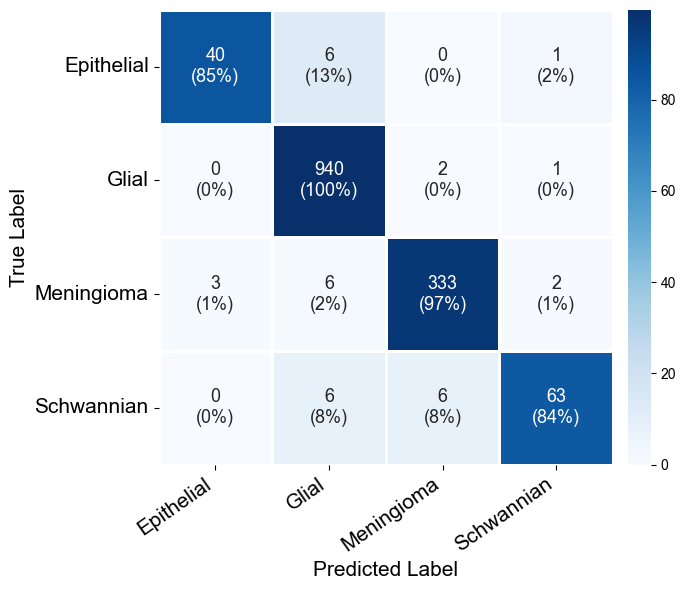

In [24]:
def plot_cm(cm, name):
    reset_style()
    cm_percent = cm.astype(float) / cm.sum(axis=1)[:, None] * 100
    annot = np.empty_like(cm).astype(str)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            annot[i, j] = f"{cm[i, j]}\n({cm_percent[i, j]:.0f}%)"
    fig, ax = plt.subplots(figsize=(7, 6))
    cax = make_axes_locatable(ax).append_axes("right", size="5%", pad=0.15)
    sns.heatmap(cm_percent, annot=annot, fmt="", cmap="Blues", square=True, linewidths=2, linecolor="white",
                xticklabels=CLASS_SHORT, yticklabels=CLASS_SHORT, annot_kws={"size": 13}, ax=ax, cbar_ax=cax)
    ax.set_xlabel("Predicted Label", fontsize=15)
    ax.set_ylabel("True Label", fontsize=15)
    ax.set_xticklabels(CLASS_SHORT, rotation=35, ha="right", fontsize=15)
    ax.set_yticklabels(CLASS_SHORT, rotation=0, fontsize=15)
    plt.tight_layout()
    save(fig, name)
    plt.show()

def cm_and_accuracy(y_true, P, panel, expected_rows, expected_acc):
    pred = np.array(CLASSES)[np.asarray(P).argmax(axis=1)]
    cm = confusion_matrix(y_true, pred, labels=CLASSES)
    print(pd.DataFrame(cm, index=[f"true {c}" for c in CLASS_SHORT], columns=[f"pred {c}" for c in CLASS_SHORT]))
    k, n = int(np.trace(cm)), int(cm.sum())
    print(f"accuracy = {k}/{n} = {k / n:.4f}")
    for c, row, exp in zip(CLASS_SHORT, cm, expected_rows):
        check(panel, f"confusion row, true {c} (pred Epi/Glial/Men/Schw)", "/".join(map(str, row)), exp,
              source="submitted panel")
    check(panel, "accuracy", f"{k}/{n} = {k / n:.3f}", expected_acc, source="brief")
    return cm

eb = pd.read_csv(MAIN / "fig6" / "6c_tumor_vit_ebrains_roc.csv")
eb_cm = pd.read_csv(MAIN / "fig6" / "6c_tumor_vit_ebrains_cm.csv")
print("6c ROC file identical to CM file:", eb.equals(eb_cm))
print("InDist counts:", eb["InDist"].value_counts().to_dict())
eb = eb[eb["InDist"] == 1].reset_index(drop=True)
print("in-distribution n =", len(eb), "| per class:", eb["Class"].value_counts().reindex(CLASSES).to_dict())
check("6c", "n in-distribution cases", len(eb), "1409")

aucs = ovr_auc(eb["Class"].values, eb[CLASSES].values, CLASSES)
display(aucs.round(4))
for (_, r), a in zip(aucs.iterrows(), ["0.973", "0.996", "0.996", "0.997"]):
    check("6c", f"AUC {r['class']}", r.AUC, a)

reset_style()
y_true_bin = np.column_stack([(eb["Class"] == c).astype(int) for c in CLASSES])
y_score = eb[CLASSES].values
fig = plt.figure(figsize=(8, 7))
for i, c in enumerate(CLASSES):
    f_, t_, _ = roc_curve(y_true_bin[:, i], y_score[:, i])
    plt.plot(f_, t_, lw=2, label=f"{c} (AUC = {auc(f_, t_):.2f})")
plt.plot([0, 1], [0, 1], color="gray", linestyle="--")
plt.xlabel("False Positive Rate", fontsize=16)
plt.ylabel("True Positive Rate", fontsize=16)
plt.legend(loc="lower right", fontsize=12)
save(fig, "Fig6c_ROC")
plt.show()

cm_c = cm_and_accuracy(eb["Class"].values, eb[CLASSES].values, "6c",
                       ["40/6/0/1", "0/940/2/1", "3/6/333/2", "0/6/6/63"], "1376/1409 = 0.977")
plot_cm(cm_c, "Fig6c_confusion_matrix")

## Fig 6d

patients in file = 100; InDist counts = {1: 82, 0: 18}
                 pred Epithelial  pred Glial  pred Meningioma  pred Schwannian
true Epithelial               19           0                1                0
true Glial                     0          28                1                0
true Meningioma                0           0               27                0
true Schwannian                0           0                1                5
accuracy = 79/82 = 0.9634


[saved] outputs\main\Fig6d_confusion_matrix.png and .pdf


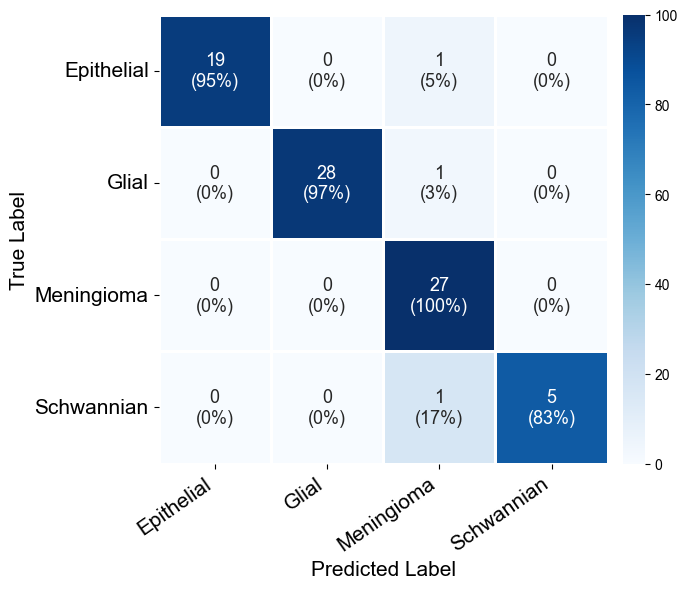

In [25]:
loc6 = pd.read_csv(MAIN / "fig6" / "6d_tumor_vit_local.csv")
print(f"patients in file = {len(loc6)}; InDist counts = {loc6['InDist'].value_counts().to_dict()}")
check("6d", "patients in file", len(loc6), "100")
loc6 = loc6[loc6["InDist"] == 1].reset_index(drop=True)
check("6d", "n in-distribution cases", len(loc6), "82")
cm_d = cm_and_accuracy(loc6["Class"].values, loc6[CLASSES].values, "6d",
                       ["19/0/1/0", "0/28/1/0", "0/0/27/0", "0/0/1/5"], "79/82 = 0.963")
plot_cm(cm_d, "Fig6d_confusion_matrix")

## Fig 6e

,Group,Device,mean_ms,sd_ms,n
0,GPU,RTX 4090,33.6,3.8,10
1,GPU,RTX 4070,45.7,4.2,10
2,GPU,RTX A4500,55.4,11.6,10
3,GPU,RTX 3070,60.6,6.5,10
4,GPU,RTX 4060,65.7,6.4,10
5,GPU,RTX 2060,76.6,7.4,10
6,GPU,GTX 1650Ti,90.0,9.5,10
7,CPU,i9-14900HX,127.6,12.9,10
8,CPU,i7-13620H,148.4,3.0,10
9,CPU,i5-1235U,196.8,10.2,10


[saved] outputs\main\Fig6e.png and .pdf


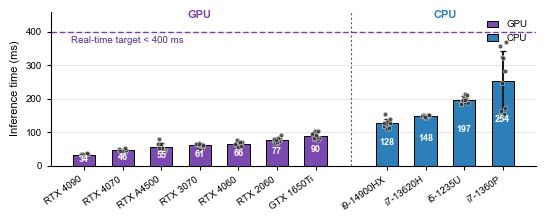

In [26]:
reset_style(rc={"font.family": "Arial", "font.size": 8, "axes.labelsize": 8, "axes.titlesize": 9, "xtick.labelsize": 7,
                "ytick.labelsize": 7})
df = pd.read_csv(MAIN / "fig6" / "6e_tumor_inference_times.csv")
summary = df.groupby(["Group", "Device"], as_index=False).agg(mean_ms=("Time_ms", "mean"), sd_ms=("Time_ms", "std"),
                                                              n=("Time_ms", "count"))
cpu_order = ["i9-14900HX", "i7-13620H", "i5-1235U", "i7-1360P"]
gpu_order = ["RTX 4090", "RTX 4070", "RTX A4500", "RTX 3070", "RTX 4060", "RTX 2060", "GTX 1650Ti"]
summary["Device"] = pd.Categorical(summary["Device"], categories=gpu_order + cpu_order, ordered=True)
gpu_summary = summary[summary["Group"] == "GPU"].sort_values("Device")
cpu_summary = summary[summary["Group"] == "CPU"].sort_values("Device")
plot_df = pd.concat([gpu_summary, cpu_summary], ignore_index=True)
display(plot_df.round(1))
expected = {"RTX 4090": "34", "RTX 4070": "46", "RTX A4500": "55", "RTX 3070": "61", "RTX 4060": "66", "RTX 2060": "77",
            "GTX 1650Ti": "90", "i9-14900HX": "128", "i7-13620H": "148", "i5-1235U": "197", "i7-1360P": "254"}
for _, r in plot_df.iterrows():
    check("6e", f"mean latency {r.Device} (ms)", r.mean_ms, expected[r.Device], source="submitted panel")
check("6e", "runs per device", int(plot_df["n"].min()) if plot_df["n"].nunique() == 1 else -1, "10")
check("6e", "all devices mean < 400 ms", bool((plot_df["mean_ms"] < 400).all()), "True")

fig, ax = plt.subplots(figsize=(5.5, 2.25))
gap = 0.85
x_gpu = np.arange(len(gpu_summary))
x_cpu = np.arange(len(cpu_summary)) + len(gpu_summary) + gap
x = np.r_[x_gpu, x_cpu]
means, sds = plot_df["mean_ms"].to_numpy(), plot_df["sd_ms"].to_numpy()
gpu_n = len(gpu_summary)
cpu_color, gpu_color = "#2C7FB8", "#7B4AB1"
bars_gpu = ax.bar(x[:gpu_n], means[:gpu_n], yerr=sds[:gpu_n], width=0.58, capsize=2.5, color=gpu_color,
                  edgecolor="black", linewidth=0.7, label="GPU", zorder=2)
bars_cpu = ax.bar(x[gpu_n:], means[gpu_n:], yerr=sds[gpu_n:], width=0.58, capsize=2.5, color=cpu_color,
                  edgecolor="black", linewidth=0.7, label="CPU", zorder=2)
rng = np.random.default_rng(42)
for i, row in plot_df.reset_index(drop=True).iterrows():
    values_i = df[(df["Device"] == row["Device"]) & (df["Group"] == row["Group"])]["Time_ms"].to_numpy()
    offsets = np.linspace(-0.09, 0.09, len(values_i))
    rng.shuffle(offsets)
    ax.scatter(x[i] + offsets, values_i, s=11, facecolor="#333333", edgecolor="white", linewidth=0.35, alpha=0.80, zorder=4)
target = 400
ax.axhline(target, color="#7B3FB2", linestyle=(0, (4, 2)), linewidth=1.0)
ax.text(x[0] - 0.35, target - 12, "Real-time target < 400 ms", ha="left", va="top", fontsize=7, color="#5B2A86")
ax.axvline(len(gpu_summary) - 0.5 + gap / 2, color="0.35", linestyle=(0, (2, 2)), linewidth=0.8)
ax.text(np.mean(x_gpu), 435, "GPU", ha="center", va="bottom", fontsize=8, fontweight="bold", color=gpu_color)
ax.text(np.mean(x_cpu), 435, "CPU", ha="center", va="bottom", fontsize=8, fontweight="bold", color=cpu_color)
for xi, m in zip(x, means):
    ax.text(xi, m * 0.55, f"{m:.0f}", ha="center", va="center", fontsize=6.5, color="white", fontweight="bold", zorder=5)
ax.set_xticks(x)
ax.set_xticklabels(plot_df["Device"], rotation=35, ha="right")
ax.set_ylabel("Inference time (ms)")
ax.set_xlabel("")
ax.set_ylim(0, 460)
ax.grid(axis="y", color="#D9D9D9", linewidth=0.5)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(0.8)
ax.spines["bottom"].set_linewidth(0.8)
ax.tick_params(width=0.8, length=3)
ax.legend(handles=[bars_gpu, bars_cpu], labels=["GPU", "CPU"], frameon=False, loc="upper right", fontsize=7,
          handlelength=1.2)
plt.tight_layout()
save(fig, "Fig6e")
plt.show()

## Fig 6f

n = 34 image regions; truth counts: {'Epithelial pattern': 9, 'Glial histology': 7, 'Meningothelial Histology': 3, 'Schwannian histology': 15}
`Class` column equals the argmax prediction in 34/34 rows; equals `Ground Truth` in 32/34 rows
                 pred Epithelial  pred Glial  pred Meningioma  pred Schwannian
true Epithelial                9           0                0                0
true Glial                     0           7                0                0
true Meningioma                0           0                3                0
true Schwannian                0           2                0               13
accuracy = 32/34 = 0.9412


[saved] outputs\main\Fig6f_confusion_matrix.png and .pdf


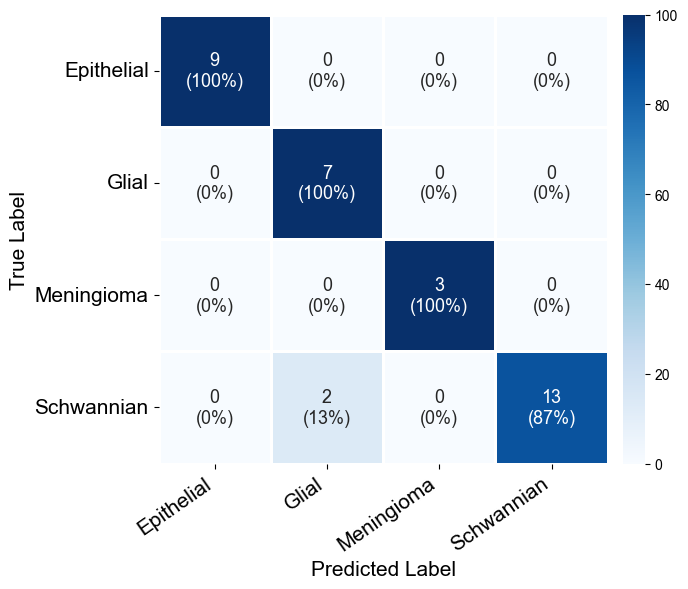

In [27]:
fz = pd.read_csv(MAIN / "fig6" / "6f_frozen section.csv")
pred_fz = np.array(CLASSES)[fz[CLASSES].values.argmax(axis=1)]
print(f"n = {len(fz)} image regions; truth counts: {fz['Ground Truth'].value_counts().reindex(CLASSES).to_dict()}")
print(f"`Class` column equals the argmax prediction in {int((fz['Class'].values == pred_fz).sum())}/{len(fz)} rows; "
      f"equals `Ground Truth` in {int((fz['Class'] == fz['Ground Truth']).sum())}/{len(fz)} rows")
check("6f", "n image regions", len(fz), "34")
check("6f", "n patients", "not in Source Data", "16",
      note="cannot be checked: the Source Data file has no patient identifier")
cm_f = cm_and_accuracy(fz["Ground Truth"].values, fz[CLASSES].values, "6f",
                       ["9/0/0/0", "0/7/0/0", "0/0/3/0", "0/2/0/13"], "32/34 = 0.941")
plot_cm(cm_f, "Fig6f_confusion_matrix")

## Fig 7e

microscope frames = 40, WSI patches = 40, pairs matched on image = 40; max distance mismatch within pairs = 0.0 µm; distance range 0-9310 µm


cellularity, microscope vs WSI: n = 40, r(38) = 0.998, 95% CI [0.996, 0.999], two-sided p = 3.614e-46


[saved] outputs\main\Fig7e.png and .pdf


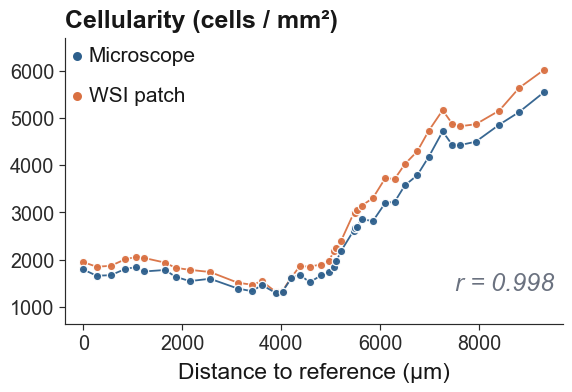

In [28]:
COLOR_MIC, COLOR_WSI = "#2D5F8C", "#D97041"
COLOR_AXIS, COLOR_LABEL, COLOR_MUTED, COLOR_HEADING = "#2A2A2A", "#171717", "#6B7280", "#171717"
s = 1.5
reset_style(rc={"font.size": 10.5 * s, "axes.titlesize": 12 * s, "axes.titleweight": "600", "axes.titlepad": 8,
                "axes.labelsize": 11 * s, "axes.labelweight": "normal", "axes.labelpad": 6, "axes.edgecolor": COLOR_AXIS,
                "axes.labelcolor": COLOR_LABEL, "axes.linewidth": 0.85, "axes.spines.top": False,
                "axes.spines.right": False, "xtick.labelsize": 9.5 * s, "ytick.labelsize": 9.5 * s,
                "xtick.direction": "out", "ytick.direction": "out", "xtick.color": COLOR_AXIS, "ytick.color": COLOR_AXIS,
                "xtick.major.width": 0.85, "ytick.major.width": 0.85, "xtick.major.size": 4, "ytick.major.size": 4,
                "legend.frameon": False, "mathtext.fontset": "custom", "mathtext.rm": "sans",
                "mathtext.it": "sans:italic", "mathtext.bf": "sans:bold"})
dist = pd.read_csv(MAIN / "fig7" / "7e_cellularity_vs_distance.csv")
dist = dist[dist["distance_um"].abs() <= 70000.0]
key = "cellularity_cells_per_mm2"
mic = dist[dist["dataset"] == "Microscope"][["image", key, "distance_um"]].rename(columns={key: "mic"})
wsi = dist[dist["dataset"] == "WSI patch"][["image", key, "distance_um"]].rename(columns={key: "wsi"})
merged = pd.merge(mic, wsi, on="image", how="inner", suffixes=("_mic", "_wsi"))
print(f"microscope frames = {len(mic)}, WSI patches = {len(wsi)}, pairs matched on image = {len(merged)}; "
      f"max distance mismatch within pairs = {np.abs(merged.distance_um_mic - merged.distance_um_wsi).max():.1f} µm; "
      f"distance range {merged.distance_um_mic.min():.0f}-{merged.distance_um_mic.max():.0f} µm")
res = pearson_report(merged["mic"], merged["wsi"], "cellularity, microscope vs WSI")
check("7e", "n pairs", res["n"], "40"); check("7e", "r", res["r"], "0.998"); check("7e", "df", res["df"], "38")
check("7e", "p", res["p"], "3.61e-46"); check("7e", "r 95% CI lower", res["lo"], "0.996")
check("7e", "r 95% CI upper", res["hi"], "0.999")

fig, ax = plt.subplots(figsize=(6.0, 4.2))
mic_df = dist[dist["dataset"] == "Microscope"].sort_values("distance_um")
wsi_df = dist[dist["dataset"] == "WSI patch"].sort_values("distance_um")
for sub, color in [(wsi_df, COLOR_WSI), (mic_df, COLOR_MIC)]:
    ax.errorbar(sub["distance_um"].values, sub[key].values, yerr=None, fmt="-", color=color, linewidth=1.3, alpha=0.95,
                marker="o", markersize=np.sqrt(36), markerfacecolor=color, markeredgecolor="white",
                markeredgewidth=0.9, zorder=3)
ax.set_title("Cellularity (cells / mm²)", loc="left", color=COLOR_HEADING)
ax.set_xlabel("Distance to reference (μm)")
ax.margins(x=0.04, y=0.14)
chip_w, chip_h, x0, y0, gap_y = 0.020, 0.022, 0.014, 0.95, 0.14
for i, (color, label) in enumerate([(COLOR_MIC, "Microscope"), (COLOR_WSI, "WSI patch")]):
    ax.scatter([x0 + chip_w / 2], [y0 - i * gap_y - chip_h / 2], s=42, color=color, zorder=10, edgecolor=color,
               linewidth=0, transform=ax.transAxes, clip_on=False)
    ax.text(x0 + chip_w + 0.014, y0 - i * gap_y - chip_h / 2, label, transform=ax.transAxes, ha="left", va="center",
            fontsize=10 * s, color=COLOR_LABEL)
ax.text(0.985, 0.10, f"$r$ = {merged['mic'].corr(merged['wsi']):.3f}", transform=ax.transAxes, ha="right", va="bottom",
        fontsize=12 * s, color=COLOR_MUTED, fontstyle="italic")
fig.tight_layout()
save(fig, "Fig7e")
plt.show()

## Fig 7f

,stratum,microscope,wsi,paired
0,Low,12,12,12
1,Medium,12,12,12
2,High,12,12,12


,metric,stratum,method,n,median,mean,q1,q3
0,cellularity_cells_per_mm2,Low,Microscope,12,1509.8,1576.9,1423.7,1798.7
1,cellularity_cells_per_mm2,Low,WSI patch,12,1668.6,1709.6,1553.8,1921.9
2,cellularity_cells_per_mm2,Medium,Microscope,12,3170.5,3090.5,2810.5,3269.5
3,cellularity_cells_per_mm2,Medium,WSI patch,12,3623.4,3588.4,3250.4,3829.2
4,cellularity_cells_per_mm2,High,Microscope,12,5040.2,5079.4,4920.0,5212.3
5,cellularity_cells_per_mm2,High,WSI patch,12,5270.4,5299.5,4970.5,5405.4
6,Size.Area_median,Low,Microscope,12,42.4,42.3,39.8,44.1
7,Size.Area_median,Low,WSI patch,12,37.0,38.0,36.5,38.9
8,Size.Area_median,Medium,Microscope,12,52.0,51.2,49.9,52.5
9,Size.Area_median,Medium,WSI patch,12,47.9,48.0,46.8,49.5


[saved] outputs\main\Fig7f_cellularity.png and .pdf


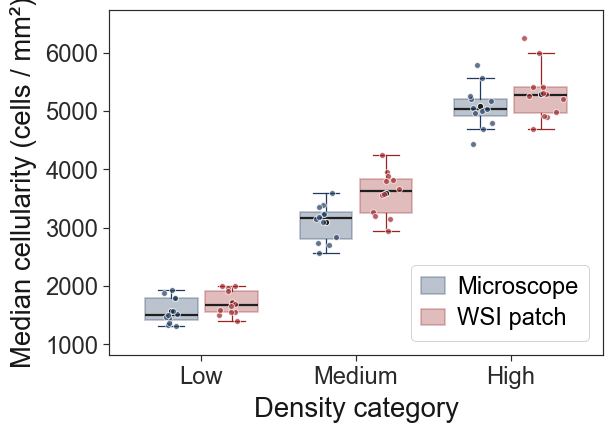

[saved] outputs\main\Fig7f_nuclear_area.png and .pdf


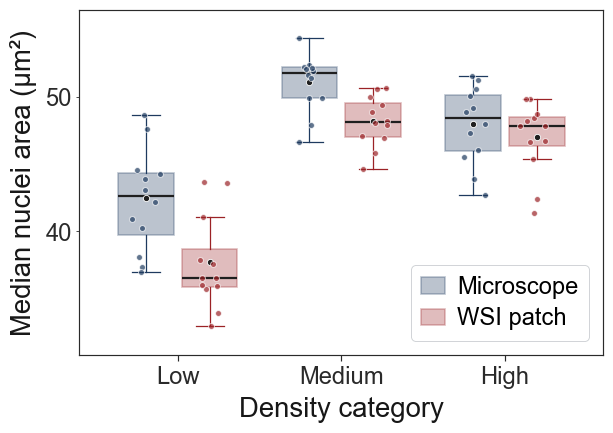

In [29]:
COLOR_MIC, COLOR_WSI = "#1E3A5F", "#9B2226"
COLOR_AXIS, COLOR_LABEL, COLOR_LEG_EDGE = "#2A2A2A", "#171717", "#BCC0C5"
s = 1.8
CATEGORY_ORDER = ["Dense_low", "Dense_medium", "Dense_high"]
CATEGORY_LABELS = {"Dense_low": "Low", "Dense_medium": "Medium", "Dense_high": "High"}
BOX_WIDTH, BOX_GAP, BOX_FACE_ALPHA, BOX_EDGE_LW, MEDIAN_LW, MEAN_MARKER_SIZE = 0.34, 0.05, 0.30, 1.2, 1.6, 4.5
POINT_SIZE, POINT_ALPHA, POINT_EDGE_LW, JITTER_AMOUNT = 18, 0.70, 0.7, 0.05
reset_style(rc={"font.size": 10.5 * s, "axes.titlesize": 12 * s, "axes.titleweight": "600", "axes.titlepad": 10,
                "axes.labelsize": 11 * s, "axes.labelweight": "normal", "axes.labelpad": 6, "axes.edgecolor": COLOR_AXIS,
                "axes.labelcolor": COLOR_LABEL, "axes.linewidth": 0.85, "axes.spines.top": True,
                "axes.spines.right": True, "xtick.labelsize": 9.5 * s, "ytick.labelsize": 9.5 * s,
                "xtick.direction": "out", "ytick.direction": "out", "xtick.color": COLOR_AXIS, "ytick.color": COLOR_AXIS,
                "xtick.major.width": 0.85, "ytick.major.width": 0.85, "xtick.minor.width": 0.6, "ytick.minor.width": 0.6,
                "xtick.major.size": 4, "ytick.major.size": 4, "ytick.minor.size": 2.2, "legend.frameon": True})
long_df = pd.read_csv(MAIN / "fig7" / "7f_dense_boxplot.csv")
long_df = long_df[long_df["category"].isin(CATEGORY_ORDER)]

def get_values(metric_key, category, method):
    m = (long_df["metric_key"] == metric_key) & (long_df["category"] == category) & (long_df["method"] == method)
    return long_df.loc[m, "value"].values.astype(float)

rows = []
for cat in CATEGORY_ORDER:
    sub = long_df[(long_df.metric_key == "cellularity_cells_per_mm2") & (long_df.category == cat)]
    mic_st, wsi_st = set(sub[sub.method == "Microscope"].stem), set(sub[sub.method == "WSI patch"].stem)
    rows.append(dict(stratum=CATEGORY_LABELS[cat], microscope=len(mic_st), wsi=len(wsi_st), paired=len(mic_st & wsi_st)))
npair = pd.DataFrame(rows)
display(npair)
for _, r in npair.iterrows():
    check("7f", f"paired patches, {r.stratum} stratum", r.paired, "12")
check("7f", "paired patches, total", int(npair.paired.sum()), "36")

desc = []
for key in ["cellularity_cells_per_mm2", "Size.Area_median"]:
    for cat in CATEGORY_ORDER:
        for meth in ["Microscope", "WSI patch"]:
            v = get_values(key, cat, meth)
            desc.append(dict(metric=key, stratum=CATEGORY_LABELS[cat], method=meth, n=len(v), median=np.median(v),
                             mean=v.mean(), q1=np.percentile(v, 25), q3=np.percentile(v, 75)))
with pd.option_context("display.float_format", "{:.1f}".format):
    display(pd.DataFrame(desc))

base = np.arange(1, len(CATEGORY_ORDER) + 1)
offset = (BOX_WIDTH + BOX_GAP) / 2
pos_mic, pos_wsi = base - offset, base + offset
rng = np.random.default_rng(42)
for _ in range(2 * len(CATEGORY_ORDER)):
    rng.normal(0.0, JITTER_AMOUNT, 12)

def plot_box(key, label, unit, log_y, name):
    fig, ax = plt.subplots(figsize=(6.5, 4.7))
    for vals, positions, color in [([get_values(key, c, "Microscope") for c in CATEGORY_ORDER], pos_mic, COLOR_MIC),
                                   ([get_values(key, c, "WSI patch") for c in CATEGORY_ORDER], pos_wsi, COLOR_WSI)]:
        bp = ax.boxplot(vals, positions=positions, widths=BOX_WIDTH, patch_artist=True, showfliers=False, notch=False,
                        showmeans=True, whiskerprops=dict(linewidth=0.9, color=color),
                        capprops=dict(linewidth=0.9, color=color), medianprops=dict(linewidth=MEDIAN_LW, color="#1f1f1f"),
                        meanprops=dict(marker="o", markerfacecolor="#1f1f1f", markeredgecolor="white",
                                       markersize=MEAN_MARKER_SIZE, markeredgewidth=0.6))
        for patch in bp["boxes"]:
            patch.set_facecolor(color); patch.set_alpha(BOX_FACE_ALPHA)
            patch.set_edgecolor(color); patch.set_linewidth(BOX_EDGE_LW)
    ax.relim(); ax.autoscale_view()
    for i, cat in enumerate(CATEGORY_ORDER):
        for meth, pos, color in [("Microscope", pos_mic, COLOR_MIC), ("WSI patch", pos_wsi, COLOR_WSI)]:
            v = get_values(key, cat, meth)
            ax.scatter(rng.normal(pos[i], JITTER_AMOUNT, len(v)), v, s=POINT_SIZE, c=color, edgecolor="white",
                       linewidth=POINT_EDGE_LW, alpha=POINT_ALPHA, zorder=4)
    ax.set_xticks(base)
    ax.set_xticklabels([CATEGORY_LABELS[c] for c in CATEGORY_ORDER])
    ax.set_xlim(0.4, len(CATEGORY_ORDER) + 0.6)
    ax.set_xlabel("Density category")
    ax.margins(y=0.10)
    if log_y:
        ax.set_yscale("log")
        fmt = FuncFormatter(lambda v, _: f"{v:g}")
        ax.yaxis.set_major_formatter(fmt)
        ax.yaxis.set_minor_formatter(fmt)
    ax.set_ylabel(label + (f" ({unit})" if unit else ""))
    handles = [mpatches.Patch(facecolor=COLOR_MIC, alpha=BOX_FACE_ALPHA, edgecolor=COLOR_MIC, linewidth=BOX_EDGE_LW,
                              label="Microscope"),
               mpatches.Patch(facecolor=COLOR_WSI, alpha=BOX_FACE_ALPHA, edgecolor=COLOR_WSI, linewidth=BOX_EDGE_LW,
                              label="WSI patch")]
    leg = ax.legend(handles=handles, loc="lower right", fontsize=9.5 * s, handlelength=1.0, handletextpad=0.5,
                    borderpad=0.45, borderaxespad=0.6, labelspacing=0.35)
    leg.get_frame().set_linewidth(0.6); leg.get_frame().set_edgecolor(COLOR_LEG_EDGE); leg.get_frame().set_facecolor("white")
    fig.tight_layout()
    save(fig, name)
    plt.show()

plot_box("cellularity_cells_per_mm2", "Median cellularity", "cells / mm²", False, "Fig7f_cellularity")
plot_box("Size.Area_median", "Median nuclei area", "μm²", True, "Fig7f_nuclear_area")

## Fig 7g

Ki-67 index, microscope vs WSI patch: n = 26, r(24) = 0.983, 95% CI [0.963, 0.993], two-sided p = 2.595e-19
least-squares fit: WSI = 0.9807 x microscope + 1.4134


[saved] outputs\main\Fig7g.png and .pdf


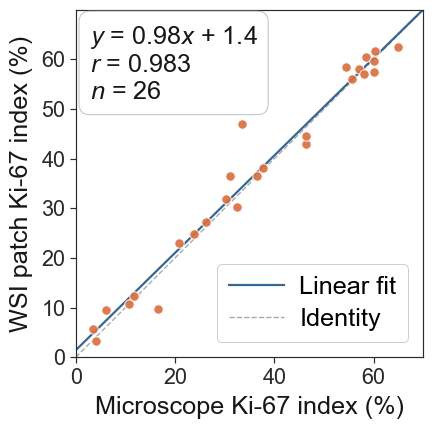

In [30]:
COLOR_DATA, COLOR_REGRESSION, COLOR_IDENTITY = "#D97041", "#2D5F8C", "#9CA1A7"
COLOR_AXIS, COLOR_LABEL, COLOR_BOX_EDGE = "#2A2A2A", "#171717", "#BCC0C5"
s = 1.3
reset_style(rc={"font.size": 10.5 * s, "axes.titlesize": 14 * s, "axes.labelsize": 14 * s, "axes.labelweight": "normal",
                "axes.labelpad": 6, "axes.edgecolor": COLOR_AXIS, "axes.labelcolor": COLOR_LABEL, "axes.linewidth": 0.85,
                "axes.spines.top": True, "axes.spines.right": True, "xtick.labelsize": 12 * s, "ytick.labelsize": 12 * s,
                "xtick.direction": "out", "ytick.direction": "out", "xtick.color": COLOR_AXIS, "ytick.color": COLOR_AXIS,
                "xtick.major.width": 0.85, "ytick.major.width": 0.85, "xtick.major.size": 4, "ytick.major.size": 4,
                "legend.frameon": True, "mathtext.fontset": "custom", "mathtext.rm": "sans",
                "mathtext.it": "sans:italic", "mathtext.bf": "sans:bold"})
paired = pd.read_csv(MAIN / "fig7" / "7g_ki67_correlation.csv")
x_ = paired["mic_ki67_pct"].astype(float).values
y_ = paired["wsi_ki67_pct"].astype(float).values
res = pearson_report(x_, y_, "Ki-67 index, microscope vs WSI patch")
lin = stats.linregress(x_, y_)
print(f"least-squares fit: WSI = {lin.slope:.4f} x microscope + {lin.intercept:.4f}")
check("7g", "n patches", res["n"], "26"); check("7g", "r", res["r"], "0.983"); check("7g", "df", res["df"], "24")
check("7g", "p", res["p"], "2.60e-19"); check("7g", "r 95% CI lower", res["lo"], "0.963")
check("7g", "r 95% CI upper", res["hi"], "0.993")
check("7g", "fit slope", lin.slope, "0.98"); check("7g", "fit intercept", lin.intercept, "1.4")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
all_vals = np.concatenate([x_, y_])
vmin, vmax = float(all_vals.min()), float(all_vals.max())
margin = (vmax - vmin) * 0.08
lo, hi = max(0.0, vmin - margin), min(100.0, vmax + margin)
identity_line, = ax.plot([lo, hi], [lo, hi], "--", color=COLOR_IDENTITY, linewidth=1.0, alpha=0.9, zorder=1, label="Identity")
regression_line, = ax.plot([lo, hi], lin.slope * np.array([lo, hi]) + lin.intercept, "-", color=COLOR_REGRESSION,
                           linewidth=1.6, alpha=0.95, zorder=2, label="Linear fit")
ax.scatter(x_, y_, s=46, c=COLOR_DATA, edgecolor="white", linewidth=0.7, zorder=3, alpha=0.92)
sign = "+" if lin.intercept >= 0 else "−"
text = "\n".join([f"$y$ = {lin.slope:.2f}$x$ {sign} {abs(lin.intercept):.1f}", f"$r$ = {res['r']:.3f}", f"$n$ = {res['n']}"])
ax.text(0.04, 0.96, text, transform=ax.transAxes, fontsize=14 * s, ha="left", va="top", color=COLOR_LABEL,
        bbox=dict(facecolor="white", alpha=1.0, edgecolor=COLOR_BOX_EDGE, linewidth=0.7, boxstyle="round,pad=0.42"))
ax.set_xlabel("Microscope Ki-67 index (%)")
ax.set_ylabel("WSI patch Ki-67 index (%)")
ax.set_xlim(lo, hi)
ax.set_ylim(lo, hi)
ax.set_aspect("equal", adjustable="box")
leg = ax.legend(handles=[regression_line, identity_line], loc="lower right", fontsize=14 * s, handlelength=2.2,
                handletextpad=0.6, borderpad=0.45, borderaxespad=0.6, labelspacing=0.35)
leg.get_frame().set_linewidth(0.7); leg.get_frame().set_edgecolor(COLOR_BOX_EDGE); leg.get_frame().set_facecolor("white")
fig.tight_layout()
save(fig, "Fig7g")
plt.show()

## Summary

In [31]:
summary = pd.DataFrame(SUMMARY)
summary.to_csv(OUT / "main_figures_statistics_summary.csv", index=False)
with pd.option_context("display.max_rows", 500, "display.max_colwidth", 80):
    display(summary)
n_bad = int((~summary["match"]).sum())
print(f"{len(summary)} statistics checked; {len(summary) - n_bad} match; {n_bad} differ.")
if n_bad:
    print(summary.loc[~summary["match"], ["panel", "quantity", "notebook", "reported", "note"]].to_string(index=False))
print(f"\nFiles written to {OUT}: {len(list(OUT.glob('*.png')))} PNG, {len(list(OUT.glob('*.pdf')))} PDF")
print(f"Total runtime: {(time.time() - _T0) / 60:.1f} min")

,panel,quantity,notebook,reported,reported_in,match,note
0,2b,GPU: runs per device and task,10,10,legend,True,
1,2b,GPU: every device has mean < 400 ms for both tasks,True,True,legend,True,
2,2b,CPU: runs per device and task,10,10,legend,True,
3,2b,CPU: configurations with mean mitosis latency < 400 ms (of 4),2,2,legend,True,
4,3c,n detections,244,244,legend,True,
5,3c,n mitoses / non-mitoses,97/147,97/147,brief,True,
6,3c,n subjects,5,5,legend,True,
7,3c,AUC,0.787,0.787,legend,True,
8,3c,"Youden threshold (0-100 scale, panel label)",31.10,31.10,submitted panel,True,
9,3c,precision at threshold (>=),0.7660,0.7659,brief,False,72/94 = 0.76596; the brief truncates instead of rounding


212 statistics checked; 209 match; 3 differ.
panel                    quantity           notebook reported                                                              note
   3c precision at threshold (>=)             0.7660   0.7659          72/94 = 0.76596; the brief truncates instead of rounding
   3c    recall at threshold (>=)             0.7423   0.7422          72/97 = 0.74227; the brief truncates instead of rounding
   6f                  n patients not in Source Data       16 cannot be checked: the Source Data file has no patient identifier

Files written to outputs\main: 33 PNG, 33 PDF
Total runtime: 0.5 min
